# ARG family–drug class SHAP comparison and new protein prediction

This self-contained notebook follows **classification → held-out evaluation and figures → SHAP tables → similarity → one saved model bundle → raw-FASTA prediction**. No variables or execution from another notebook are required.

Both targets use the same unique CARD ARO proteins, descriptors, outer folds, and SHAP aggregation population. Family and drug-class membership are fitted as independent binary LightGBM models; multiple CARD annotations are preserved. Prediction reports one primary family, ranked alternatives, and all drug classes passing their own thresholds. Scores from class-weighted models are **not calibrated probabilities**.

The existing family top-15 table cannot support full-profile correlation. We regenerate complete family **and** drug-class SHAP profiles to keep their populations and validation design aligned, and export a separate comparison with the existing family top-15 results. Existing result files are read only.

**Minimum support is 10 unique ARO records for each positive and negative state**, with group support and fold coverage checked separately. `Max SHAP <= 2.0` means `max_feature(mean_heldout(abs(SHAP))) <= 2.0`, applied to each target label. It is the requested screening rule, not a universal mathematical validity bound or evidence of prediction reliability.

Run the sections in order for training. Once the bundle exists, prediction in a fresh kernel requires only the cells labelled **Inference helpers**, **Feature extraction helpers**, and **Fresh query configuration**. All cells are delivered unexecuted; there are no automatic installation cells.

In [1]:
from pathlib import Path

PROJECT_ROOT = Path("/home/user/Pranjal-11-12-2025/ESKAPE_ARG_Family")
CARD_ROOT = PROJECT_ROOT / "CARD_DATA" / "card-data"
FINAL_RESULTS = CARD_ROOT / "refined_details" / "Final_Results"
PFEATURE_CSV = FINAL_RESULTS / "Drug_Class_Fastas_pfeatures" / "all_families_features.csv"
PROFET_CSV = FINAL_RESULTS / "Drug_Class_Fastas_profet" / "all_families_profet_features.csv"
ARO_INDEX_TSV = CARD_ROOT / "refined_details" / "aro_index.tsv"
PROTEIN_FASTA = CARD_ROOT / "protein_fasta_protein_homolog_model.fasta"
LEGACY_FAMILY_SHAP_CSV = FINAL_RESULTS / "ML_on_features_ARG" / "results" / "family_classifiers" / "top_features_shap.csv"
OUTPUT_DIR = FINAL_RESULTS / "ML_ARG_family_drug_class_comparison"
MODEL_PATH = OUTPUT_DIR / "models" / "arg_family_drug_class_bundle.zip"

MIN_FAMILY_N = 10
MIN_DRUG_CLASS_N = 10
N_FOLDS = 5
INNER_FOLDS = 3  # Inner grouped CV selects thresholds without looking at the outer test fold.
RANDOM_SEED = 0
SEQUENCE_CLUSTER_CSV = None  # Optional CSV: aro_accession, cluster_id; must cover every ARO.
CV_GROUP_RADIUS = 1.0       # Descriptor-based proxy only when no sequence clusters are supplied.
EXPECTED_FEATURE_COUNT = 996
EXCLUDE_FEATURE_PREFIXES = ("PRI_", "RRI_")
TOP_N_FEATURES = 15
SHAP_SAFETY_THRESHOLD = 2.0
SHAP_BATCH_SIZE = 256
MIN_RELIABILITY_AP = 0.50
MIN_RELIABILITY_F1 = 0.50
OOD_QUANTILE = 0.99
OOD_PCA_COMPONENTS = 50
THRESHOLD_GRID = [i / 100 for i in range(5, 96)]
RESUME_CV = True  # Reuse only per-label caches whose complete run fingerprint matches.
LGB_PARAMS = dict(
    objective="binary", n_estimators=300, num_leaves=15, learning_rate=0.05,
    min_child_samples=10, reg_lambda=1.0, is_unbalance=True, verbosity=-1,
    n_jobs=2, deterministic=True, force_col_wise=True,
)

In [2]:
import csv
import hashlib
import io
import json
import math
import re
import zipfile
from collections import defaultdict
from datetime import datetime, timezone
from importlib.metadata import version
import numpy as np
import pandas as pd
import lightgbm as lgb
import shap
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from scipy.stats import spearmanr
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.neighbors import radius_neighbors_graph, NearestNeighbors
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, average_precision_score, confusion_matrix, f1_score,
    hamming_loss, precision_score, recall_score, roc_auc_score, roc_curve,
    precision_recall_curve,
)
PACKAGE_VERSIONS = {name: version(name) for name in (
    "numpy", "pandas", "scikit-learn", "lightgbm", "shap", "matplotlib", "biopython", "pfeature"
)}
print(PACKAGE_VERSIONS)
# Dependencies should be installed in the notebook kernel before execution.

/home/user/miniforge3/envs/jupyter/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{'numpy': '2.4.4', 'pandas': '2.3.3', 'scikit-learn': '1.8.0', 'lightgbm': '4.7.0', 'shap': '0.52.0', 'matplotlib': '3.10.8', 'biopython': '1.86', 'pfeature': '1.4'}


## 1. Reconcile protein features and CARD memberships

Pfeature and the project's **ProFET-style Biopython features** are joined by class and sequence ID; ARO copies must have identical retained descriptors. Each ARO then contributes one feature row. Original protein hashes keep identical sequences together in validation. Family annotations and family–drug-class edges are read from the configured CARD index; no family is inferred from a filename. Proteins annotated to rare labels remain in the population as negatives for other binary targets.

In [3]:
def canonical_aro(value):
    value = str(value).strip()
    hits = set(re.findall(r"ARO:(\d+)", value))
    if not hits:
        match = re.fullmatch(r"(?:f\d+_)+(\d+)", value)
        if match:
            hits = {match.group(1)}
    if not hits and value.isdigit():
        hits = {value}
    if len(hits) != 1:
        raise ValueError(f"Cannot resolve exactly one ARO accession from {value!r}")
    return "ARO:" + next(iter(hits))


def class_file_label(label):
    return re.sub(r"[^A-Za-z0-9._-]+", "_", label.strip()).strip("._")


def file_sha256(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


def read_drug_feature_table(path):
    with Path(path).open(newline="", encoding="utf-8-sig") as handle:
        columns = next(csv.reader(handle))
    if len(columns) != len(set(columns)):
        raise ValueError(f"Duplicate column names in {path}")
    frame = pd.read_csv(path, dtype={"sequence_id": str}, keep_default_na=True)
    label_columns = [c for c in ("drug_class", "Drug Class", "family") if c in frame]
    if len(label_columns) != 1 or "sequence_id" not in frame:
        raise ValueError(f"{path}: expected sequence_id and exactly one class-label column")
    frame = frame.rename(columns={label_columns[0]: "drug_class"})
    if frame[["drug_class", "sequence_id"]].isna().any().any():
        raise ValueError(f"Missing IDs/labels in {path}")
    for column in ("drug_class", "sequence_id"):
        frame[column] = frame[column].astype(str).str.strip()
        if frame[column].eq("").any():
            raise ValueError(f"Blank {column} in {path}")
    if frame.duplicated(["drug_class", "sequence_id"]).any():
        raise ValueError(f"Duplicate (class, sequence_id) keys in {path}; check repeated master-file merges")
    return frame


def read_card_drug_lookup(path):
    table = pd.read_csv(path, sep="\t", dtype=str, keep_default_na=False)
    required = {"ARO Accession", "Drug Class"}
    if not required.issubset(table.columns):
        raise ValueError(f"CARD index needs {sorted(required)}")
    lookup = defaultdict(set)
    for aro, labels in table[["ARO Accession", "Drug Class"]].itertuples(index=False, name=None):
        lookup[canonical_aro(aro)].update(x.strip() for x in labels.split(";") if x.strip())
    labels = sorted({label for values in lookup.values() for label in values})
    reverse = {}
    for label in labels:
        slug = class_file_label(label)
        if slug in reverse and reverse[slug] != label:
            raise ValueError(f"Drug-class filename collision: {label!r} and {reverse[slug]!r}")
        reverse[slug] = label
    return dict(lookup), reverse


def protein_hashes_by_aro(path):
    hashes = {}
    header, parts = None, []

    def store_record(h, sequence):
        aro = canonical_aro(h)
        if not sequence:
            raise ValueError(f"Empty sequence for {aro}")
        digest = hashlib.sha256(sequence.upper().encode()).hexdigest()
        if aro in hashes and hashes[aro] != digest:
            raise ValueError(f"Multiple different protein sequences for {aro}")
        hashes[aro] = digest

    with Path(path).open(encoding="utf-8") as handle:
        for line in handle:
            if line.startswith(">"):
                if header is not None:
                    store_record(header, "".join(parts))
                header, parts = line[1:].strip(), []
            elif line.strip():
                if header is None:
                    raise ValueError("Protein FASTA contains sequence before its first header")
                parts.append(line.strip())
    if header is not None:
        store_record(header, "".join(parts))
    return hashes


def load_drug_training_data(pfeature_csv, profet_csv, aro_tsv, protein_fasta, excluded_prefixes):
    pf = read_drug_feature_table(pfeature_csv)
    pr = read_drug_feature_table(profet_csv)
    keys = ["drug_class", "sequence_id"]
    pf_features = [c for c in pf.columns if c not in keys]
    pr_features = [c for c in pr.columns if c not in keys]
    collisions = set(pf_features) & set(pr_features)
    if collisions:
        raise ValueError(f"Descriptor names occur in both extractors: {sorted(collisions)}")

    merged = pf.merge(pr, on=keys, how="outer", validate="one_to_one", indicator=True)
    if not merged["_merge"].eq("both").all():
        raise ValueError(f"Unmatched extraction rows: {merged['_merge'].value_counts().to_dict()}")
    merged = merged.drop(columns="_merge")
    merged["aro_accession"] = merged["sequence_id"].map(canonical_aro)
    lookup, reverse_labels = read_card_drug_lookup(aro_tsv)
    missing_aros = sorted(set(merged["aro_accession"]) - set(lookup))
    if missing_aros:
        raise ValueError(f"ARO accessions absent from CARD: {missing_aros[:10]}")

    def resolve_label(label):
        if label in reverse_labels.values():
            return label
        if label not in reverse_labels:
            raise ValueError(f"Unknown drug-class file label: {label}")
        return reverse_labels[label]

    merged["drug_class"] = merged["drug_class"].map(resolve_label)
    observed = merged.groupby("aro_accession")["drug_class"].agg(set)
    mismatched = [aro for aro, labels in observed.items() if labels != lookup[aro]]
    if mismatched:
        raise ValueError(f"Drug-class copies do not match CARD annotations: {mismatched[:10]}")

    raw_features = pf_features + pr_features
    excluded = [c for c in raw_features if c.startswith(tuple(excluded_prefixes))]
    features = [c for c in raw_features if c not in excluded]
    if not features:
        raise ValueError("No retained descriptors")
    numeric = merged[features].apply(pd.to_numeric, errors="raise").astype(float)
    numeric = numeric.replace([np.inf, -np.inf], np.nan)
    unique_counts = numeric.groupby(merged["aro_accession"]).nunique(dropna=False)
    inconsistent = unique_counts.columns[unique_counts.gt(1).any()].tolist()
    if inconsistent:
        raise ValueError(f"Same-ARO descriptor conflicts; correct the extracts first: {inconsistent[:20]}")
    keep = ~merged["aro_accession"].duplicated()
    meta = merged.loc[keep, ["aro_accession", "sequence_id"]].reset_index(drop=True)
    X_df = numeric.loc[keep].reset_index(drop=True)
    if X_df.isna().all(axis=1).any():
        raise ValueError("At least one protein has no usable numeric descriptors")
    hashes = protein_hashes_by_aro(protein_fasta)
    meta["sequence_sha256"] = meta["aro_accession"].map(hashes)
    if meta["sequence_sha256"].isna().any():
        raise ValueError("Some feature AROs are absent from the protein FASTA")
    label_sets = [lookup[aro] for aro in meta["aro_accession"]]
    labels = sorted(set().union(*label_sets))
    Y = np.array([[label in memberships for label in labels] for memberships in label_sets], dtype=np.uint8)
    feature_sources = {c: "Pfeature" if c in pf_features else "ProFET" for c in features}
    audit = {
        "input_assignment_rows": len(merged), "unique_aro_records": len(meta),
        "represented_drug_classes": len(labels),
        "multi_label_proteins": int((Y.sum(axis=1) > 1).sum()),
        "retained_features": len(features), "excluded_features": excluded,
        "missing_numeric_values": int(X_df.isna().sum().sum()),
    }
    return meta, X_df, labels, Y, feature_sources, audit

In [4]:
def read_card_families_and_edges(path):
    table = pd.read_csv(path, sep="\t", dtype=str, keep_default_na=False)
    required = {"ARO Accession", "AMR Gene Family", "Drug Class"}
    if not required.issubset(table.columns):
        raise ValueError(f"CARD index requires {sorted(required)}")
    families, edges = defaultdict(set), set()
    for _, row in table.iterrows():
        aro = canonical_aro(row["ARO Accession"])
        fams = {x.strip() for x in row["AMR Gene Family"].split(";") if x.strip()}
        drugs = {x.strip() for x in row["Drug Class"].split(";") if x.strip()}
        families[aro].update(fams)
        edges.update((family, drug) for family in fams for drug in drugs)
    return dict(families), edges

meta, X_df, drug_labels_all, Y_drug_all, feature_sources, data_audit = load_drug_training_data(
    PFEATURE_CSV, PROFET_CSV, ARO_INDEX_TSV, PROTEIN_FASTA, EXCLUDE_FEATURE_PREFIXES
)
family_lookup, card_edges = read_card_families_and_edges(ARO_INDEX_TSV)
missing_family = [aro for aro in meta["aro_accession"] if not family_lookup.get(aro)]
if missing_family:
    raise ValueError(f"Missing CARD family annotations: {missing_family[:10]}")
family_labels_all = sorted(set().union(*(family_lookup[aro] for aro in meta["aro_accession"])))
Y_family_all = np.array([
    [label in family_lookup[aro] for label in family_labels_all] for aro in meta["aro_accession"]
], dtype=np.uint8)
feature_names = X_df.columns.tolist()
if len(feature_names) != EXPECTED_FEATURE_COUNT:
    raise ValueError(f"Expected {EXPECTED_FEATURE_COUNT} features, found {len(feature_names)}; review extraction/schema changes.")
X = X_df.to_numpy(dtype=float)
data_audit.update(represented_families=len(family_labels_all),
                  multiple_family_memberships=int((Y_family_all.sum(axis=1) > 1).sum()))
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR = OUTPUT_DIR / "figures"
FIGURES_DIR.mkdir(exist_ok=True)
CACHE_DIR = OUTPUT_DIR / "cv_cache"
CACHE_DIR.mkdir(exist_ok=True)
(OUTPUT_DIR / "data_audit.json").write_text(json.dumps(data_audit, indent=2))
display(pd.Series(data_audit, name="value"))

input_assignment_rows                                                      12913
unique_aro_records                                                          6059
represented_drug_classes                                                      39
multi_label_proteins                                                        3951
retained_features                                                            996
excluded_features              [RRI_A, RRI_C, RRI_D, RRI_E, RRI_F, RRI_G, RRI...
missing_numeric_values                                                        33
represented_families                                                         396
multiple_family_memberships                                                  136
Name: value, dtype: object

## 2. Shared grouped folds and support exclusions

External sequence-identity clusters are preferred. The fallback is the earlier notebook's descriptor-radius grouping plus exact-sequence hash links. Its global scaling is used **only to define split groups**; model inputs use LightGBM's native NaN handling. This fallback does not establish performance on distant homologues.

All family and drug labels share the same outer folds. Labels absent from either target state in an outer fold are excluded with a recorded reason. Within each outer training partition, a separate grouped CV selects each binary threshold by F1 (ties favour the higher threshold). If inner grouped CV is infeasible, use `0.50` and record the fallback. Outer-test rows never choose their own threshold. Final deployment thresholds are chosen from the complete OOF scores and are not used to report the outer F1.

In [5]:
def build_cv_groups(X_df, meta, cluster_csv=None, radius=1.0):
    n = len(meta)
    row_links, col_links = [], []
    if cluster_csv is not None:
        clusters = pd.read_csv(cluster_csv, dtype=str, keep_default_na=False)
        if not {"aro_accession", "cluster_id"}.issubset(clusters.columns):
            raise ValueError("Sequence cluster CSV needs aro_accession, cluster_id")
        clusters["aro_accession"] = clusters["aro_accession"].map(canonical_aro)
        if clusters["aro_accession"].duplicated().any() or clusters["cluster_id"].str.strip().eq("").any():
            raise ValueError("Duplicate AROs or blank cluster identifiers")
        mapped = meta["aro_accession"].map(clusters.set_index("aro_accession")["cluster_id"])
        if mapped.isna().any():
            raise ValueError("Sequence cluster CSV does not cover every feature ARO")
        base_groups = mapped.to_numpy()
        graph = coo_matrix((n, n), dtype=np.uint8).tocsr()
        source = "external_sequence_clusters"
    else:
        if radius <= 0:
            raise ValueError("CV_GROUP_RADIUS must be positive")
        grouping_only = X_df.fillna(X_df.median()).fillna(0.0)
        grouping_scaled = StandardScaler().fit_transform(grouping_only)
        graph = radius_neighbors_graph(
            grouping_scaled, radius=radius, mode="connectivity",
            include_self=True, n_jobs=2,
        )
        base_groups = np.arange(n)
        source = "approximate_descriptor_radius"

    for group_values in (base_groups, meta["sequence_sha256"].to_numpy()):
        first = {}
        for index, value in enumerate(group_values):
            if value in first:
                row_links.append(first[value])
                col_links.append(index)
            else:
                first[value] = index
    if row_links:
        links = coo_matrix((np.ones(len(row_links)), (row_links, col_links)), shape=(n, n))
        graph = graph + links + links.T
    _, groups = connected_components(graph, directed=False)
    return groups, source


def choose_shared_folds(Y, groups, max_folds, seed):
    if Y.shape[1] == 0:
        raise ValueError("No classes satisfy the sample/group support requirements")
    support = Y.sum(axis=0)
    anchor = np.where(Y != 0, support[None, :], np.inf).argmin(axis=1)
    anchor[Y.sum(axis=1) == 0] = Y.shape[1]
    best = None
    upper = min(max_folds, len(np.unique(groups)))
    for n_splits in range(upper, 1, -1):
        splitter = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
        folds = list(splitter.split(np.zeros((len(Y), 1)), anchor, groups))
        valid = np.ones(Y.shape[1], dtype=bool)
        for train, test in folds:
            if set(groups[train]) & set(groups[test]):
                raise AssertionError("CV group leakage")
            for indices in (train, test):
                positives = Y[indices].sum(axis=0)
                valid &= (positives > 0) & (positives < len(indices))
        if best is None or valid.sum() > best[1].sum():
            best = (folds, valid)
        if valid.all():
            return folds, valid
    if best is None or not best[1].any():
        raise ValueError("No class supports a two-sided grouped validation split")
    return best

In [6]:
if min(MIN_FAMILY_N, MIN_DRUG_CLASS_N) < 10:
    raise ValueError("Both minimum-support filters must be at least 10.")
if min(N_FOLDS, INNER_FOLDS) < 2 or SHAP_BATCH_SIZE < 1:
    raise ValueError("Invalid fold count or SHAP batch size")
if not 0 < OOD_QUANTILE < 1 or TOP_N_FEATURES < 1 or SHAP_SAFETY_THRESHOLD < 0:
    raise ValueError("Invalid comparison/applicability configuration")
if not THRESHOLD_GRID or any(not 0 < t < 1 for t in THRESHOLD_GRID):
    raise ValueError("Threshold candidates must lie strictly between zero and one")
cv_groups, grouping_source = build_cv_groups(X_df, meta, SEQUENCE_CLUSTER_CSV, CV_GROUP_RADIUS)
all_targets = [("family", x) for x in family_labels_all] + [("drug_class", x) for x in drug_labels_all]
Y_all = np.column_stack([Y_family_all, Y_drug_all])
support_rows = []
for j, (kind, label) in enumerate(all_targets):
    y = Y_all[:, j]
    pos, neg = int(y.sum()), int((1-y).sum())
    pg, ng = len(np.unique(cv_groups[y == 1])), len(np.unique(cv_groups[y == 0]))
    minimum = MIN_FAMILY_N if kind == "family" else MIN_DRUG_CLASS_N
    reason = "below_minimum_support" if min(pos, neg) < minimum else ""
    if not reason and min(pg, ng) < 2:
        reason = "fewer_than_two_groups_per_target_state"
    support_rows.append(dict(target_type=kind, label=label, n_positive=pos, n_negative=neg,
                             positive_groups=pg, negative_groups=ng, exclusion_reason=reason))
support = pd.DataFrame(support_rows)
candidates = np.flatnonzero(support["exclusion_reason"].eq(""))
folds, eligible = choose_shared_folds(Y_all[:, candidates], cv_groups, N_FOLDS, RANDOM_SEED)
for j in candidates[~eligible]:
    support.loc[j, "exclusion_reason"] = "missing_target_state_in_outer_fold"
selected_indices = candidates[eligible]
targets = [all_targets[j] for j in selected_indices]
Y = Y_all[:, selected_indices]
if {k for k, _ in targets} != {"family", "drug_class"}:
    raise ValueError("Both family and drug-class targets are required")
support["modelled"] = support["exclusion_reason"].eq("")
fold_id = np.full(len(X), -1, dtype=int)
fold_rows = []
for number, (train, test) in enumerate(folds):
    if (fold_id[test] != -1).any() or set(cv_groups[train]) & set(cv_groups[test]):
        raise AssertionError("Outer-fold overlap or group leakage")
    fold_id[test] = number
    for j, (kind, label) in enumerate(targets):
        fold_rows.append(dict(fold=number, target_type=kind, label=label,
            train_positive=int(Y[train,j].sum()), test_positive=int(Y[test,j].sum()),
            train_negative=int((1-Y[train,j]).sum()), test_negative=int((1-Y[test,j]).sum())))
assert (fold_id >= 0).all()
support.to_csv(OUTPUT_DIR / "target_support_and_exclusions.csv", index=False)
pd.DataFrame(fold_rows).to_csv(OUTPUT_DIR / "fold_target_support.csv", index=False)
meta.assign(cv_group=cv_groups, fold=fold_id).to_csv(OUTPUT_DIR / "sequence_fold_manifest.csv", index=False)
run_config = dict(schema_version=1, algorithm_revision="paired_cv_v1", targets=targets,
    feature_names=feature_names, params=LGB_PARAMS, seed=RANDOM_SEED, inner_folds=INNER_FOLDS,
    threshold_grid=THRESHOLD_GRID, grouping=grouping_source, radius=CV_GROUP_RADIUS,
    fold_id=fold_id.tolist(), package_versions=PACKAGE_VERSIONS,
    inputs={str(p): file_sha256(p) for p in (PFEATURE_CSV, PROFET_CSV, ARO_INDEX_TSV, PROTEIN_FASTA)})
if SEQUENCE_CLUSTER_CSV is not None:
    run_config["cluster_file_sha256"] = file_sha256(SEQUENCE_CLUSTER_CSV)
RUN_FINGERPRINT = hashlib.sha256(json.dumps(run_config, sort_keys=True).encode()).hexdigest()
(OUTPUT_DIR / "run_config.json").write_text(json.dumps(run_config, indent=2))
print(f"{len(X)} AROs, {len(feature_names)} descriptors, {len(folds)} outer folds ({grouping_source})")
display(support.groupby(["target_type", "modelled"]).size().rename("labels"))

/home/user/miniforge3/envs/jupyter/lib/python3.12/site-packages/sklearn/model_selection/_split.py:1037: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=5.
  warnings.warn(


6059 AROs, 996 descriptors, 5 outer folds (approximate_descriptor_radius)


target_type  modelled
drug_class   False        12
             True         27
family       False       312
             True         84
Name: labels, dtype: int64

## 3. Train classifiers, select thresholds, and collect held-out SHAP

This is the expensive section: each target uses outer CV, inner CV for threshold selection, and held-out Tree SHAP. Work is sequential with two LightGBM threads by default. Per-target checkpoints can resume an interrupted run; configuration, input hashes, folds and package versions must match.

Global SHAP is the row-weighted mean absolute attribution across **all** held-out proteins, including negatives, in raw-margin units. Tree-path-dependent training path counts define each fold model's reference distribution. Every explanation must reconstruct its model's raw margin. SHAP values describe model behaviour and correlated descriptors can share or exchange importance.

In [7]:
def pick_threshold(y, scores, grid):
    candidates = np.asarray(sorted(set(grid)), dtype=float)
    values = np.array([f1_score(y, scores >= t, zero_division=0) for t in candidates])
    return float(candidates[np.flatnonzero(np.isclose(values, values.max()))[-1]])


def inner_threshold(X_train, y_train, groups_train, seed):
    max_splits = min(INNER_FOLDS, len(np.unique(groups_train)))
    for count in range(max_splits, 1, -1):
        splitter = StratifiedGroupKFold(n_splits=count, shuffle=True, random_state=seed)
        splits = list(splitter.split(X_train, y_train, groups_train))
        if any(len(np.unique(y_train[a])) != 2 or len(np.unique(y_train[b])) != 2 for a,b in splits):
            continue
        scores = np.full(len(y_train), np.nan)
        for train, test in splits:
            assert not set(groups_train[train]) & set(groups_train[test])
            model = lgb.LGBMClassifier(random_state=seed, **LGB_PARAMS)
            model.fit(X_train[train], y_train[train])
            scores[test] = model.booster_.predict(X_train[test], num_threads=2)
        assert np.isfinite(scores).all()
        return pick_threshold(y_train, scores, THRESHOLD_GRID), f"inner_grouped_{count}_fold"
    return 0.50, "fallback_0.50_insufficient_inner_group_support"


def checked_explanation(model, batch, names):
    booster = model.booster_ if hasattr(model, "booster_") else model
    explainer = shap.TreeExplainer(booster, model_output="raw",
        feature_perturbation="tree_path_dependent", feature_names=names)
    explanation = explainer(batch, check_additivity=True)
    if explanation.values.ndim == 3 and explanation.values.shape[-1] == 2:
        explanation = explanation[..., 1]
    values = np.asarray(explanation.values)
    if values.shape != batch.shape or not np.isfinite(values).all():
        raise ValueError("Invalid SHAP shape or non-finite attributions")
    base = np.asarray(explanation.base_values).reshape(-1)
    reconstruction = base + values.sum(axis=1)
    expected = booster.predict(batch, raw_score=True, num_threads=2)
    np.testing.assert_allclose(reconstruction, expected, rtol=1e-5, atol=1e-5)
    return explanation, float(np.max(np.abs(reconstruction - expected)))


def fit_target(j, kind, label):
    y = Y[:, j]
    scores, decisions = np.full(len(X), np.nan), np.zeros(len(X), dtype=np.uint8)
    fold_importance, fold_records = [], []
    demo_model = None
    for number, (train, test) in enumerate(folds):
        threshold, threshold_source = inner_threshold(X[train], y[train], cv_groups[train], RANDOM_SEED + number)
        model = lgb.LGBMClassifier(random_state=RANDOM_SEED, **LGB_PARAMS)
        model.fit(X[train], y[train])
        scores[test] = model.booster_.predict(X[test], num_threads=2)
        decisions[test] = scores[test] >= threshold
        summed = np.zeros(X.shape[1])
        error = 0.0
        for start in range(0, len(test), SHAP_BATCH_SIZE):
            batch = X[test[start:start+SHAP_BATCH_SIZE]]
            explanation, err = checked_explanation(model, batch, feature_names)
            summed += np.abs(explanation.values).sum(axis=0)
            error = max(error, err)
        fold_importance.append(summed / len(test))
        fold_records.append(dict(fold=number, target_type=kind, label=label, n_explained=len(test),
            threshold=threshold, threshold_source=threshold_source,
            ap=average_precision_score(y[test], scores[test]),
            roc_auc=roc_auc_score(y[test], scores[test]),
            f1=f1_score(y[test], decisions[test], zero_division=0), max_additivity_error=error))
        if number == 0:
            demo_model = model.booster_.model_to_string()
        print(f"{kind}: {label} | outer fold {number+1}/{len(folds)}", flush=True)
    if not np.isfinite(scores).all() or ((scores < 0) | (scores > 1)).any():
        raise AssertionError("Incomplete or invalid OOF scores")
    fold_importance = np.asarray(fold_importance)
    mean_importance = np.average(fold_importance, axis=0, weights=[len(b) for _, b in folds])
    return dict(scores=scores, decisions=decisions, mean_abs_shap=mean_importance,
                fold_importance=fold_importance, fold_records=fold_records, demo_model=demo_model)


def cache_target(j, kind, label):
    path = CACHE_DIR / f"target_{j:04d}_{RUN_FINGERPRINT[:12]}.npz"
    if RESUME_CV and path.exists():
        with np.load(path, allow_pickle=False) as z:
            if str(z["fingerprint"].item()) != RUN_FINGERPRINT:
                raise ValueError("Stale target cache")
            result = {k: z[k].copy() for k in ("scores", "decisions", "mean_abs_shap", "fold_importance")}
            result["fold_records"] = json.loads(str(z["fold_records"].item()))
            result["demo_model"] = str(z["demo_model"].item())
        assert result["scores"].shape == (len(X),) and result["mean_abs_shap"].shape == (X.shape[1],)
        print(f"Resumed {kind}: {label}", flush=True)
        return result
    result = fit_target(j, kind, label)
    temp = path.with_suffix(".tmp")
    with temp.open("wb") as stream:
        np.savez_compressed(stream, fingerprint=np.array(RUN_FINGERPRINT),
            scores=result["scores"], decisions=result["decisions"], mean_abs_shap=result["mean_abs_shap"],
            fold_importance=result["fold_importance"], fold_records=np.array(json.dumps(result["fold_records"])),
            demo_model=np.array(result["demo_model"]))
    temp.replace(path)
    return result

In [8]:
# LONG-RUNNING TRAINING CELL — execute explicitly when ready.
cv_results = [cache_target(j, kind, label) for j, (kind, label) in enumerate(targets)]
oof_scores = np.column_stack([r["scores"] for r in cv_results])
oof_decisions = np.column_stack([r["decisions"] for r in cv_results])
importance = np.vstack([r["mean_abs_shap"] for r in cv_results])
fold_metrics = pd.DataFrame([row for r in cv_results for row in r["fold_records"]])
fold_metrics.to_csv(OUTPUT_DIR / "fold_validation_metrics.csv", index=False)
np.savez_compressed(OUTPUT_DIR / "paired_oof_cache.npz", y_true=Y, scores=oof_scores,
    decisions=oof_decisions, fold=fold_id, target_types=np.array([k for k,_ in targets]),
    labels=np.array([x for _,x in targets]), aro_accession=meta["aro_accession"].to_numpy(dtype=str),
    feature_names=np.array(feature_names), mean_abs_shap=importance)

family: 16S rRNA methyltransferase (G1405) | outer fold 1/5
family: 16S rRNA methyltransferase (G1405) | outer fold 2/5
family: 16S rRNA methyltransferase (G1405) | outer fold 3/5
family: 16S rRNA methyltransferase (G1405) | outer fold 4/5
family: 16S rRNA methyltransferase (G1405) | outer fold 5/5
family: AAC(3) | outer fold 1/5
family: AAC(3) | outer fold 2/5
family: AAC(3) | outer fold 3/5
family: AAC(3) | outer fold 4/5
family: AAC(3) | outer fold 5/5
family: AAC(6') | outer fold 1/5
family: AAC(6') | outer fold 2/5
family: AAC(6') | outer fold 3/5
family: AAC(6') | outer fold 4/5
family: AAC(6') | outer fold 5/5
family: AAC(6')-Ib-cr | outer fold 1/5
family: AAC(6')-Ib-cr | outer fold 2/5
family: AAC(6')-Ib-cr | outer fold 3/5
family: AAC(6')-Ib-cr | outer fold 4/5
family: AAC(6')-Ib-cr | outer fold 5/5
family: ACC beta-lactamase | outer fold 1/5
family: ACC beta-lactamase | outer fold 2/5
family: ACC beta-lactamase | outer fold 3/5
family: ACC beta-lactamase | outer fold 4/5
fami

## 4. Validation metrics, confusion matrices, ROC and PR curves

AP and AUROC use outer-held-out scores. Binary F1/precision/recall use thresholds chosen within each outer training partition. The final deployment threshold is shown separately; no F1 measured on its own tuning data is reported as independent validation. A primary-family confusion matrix uses the largest independent binary score and is restricted to proteins with exactly one supported true family; other rows are counted and reported separately.

`weak_model` flags AP or nested-threshold F1 below 0.50. Weak targets remain in the tables and figures. Scores are ranking/decision outputs, not calibrated resistance probabilities.

In [9]:
metric_rows = []
for j, (kind, label) in enumerate(targets):
    y, score, pred = Y[:,j], oof_scores[:,j], oof_decisions[:,j]
    ap, f1 = average_precision_score(y, score), f1_score(y, pred, zero_division=0)
    metric_rows.append(dict(target_type=kind, label=label, n_positive=int(y.sum()),
        n_negative=int((1-y).sum()), ap=ap, roc_auc=roc_auc_score(y, score), f1=f1,
        precision=precision_score(y,pred,zero_division=0), recall=recall_score(y,pred,zero_division=0),
        accuracy=accuracy_score(y,pred), f1_at_0_50=f1_score(y,score>=0.5,zero_division=0),
        deployment_threshold=pick_threshold(y,score,THRESHOLD_GRID),
        weak_model=bool(ap < MIN_RELIABILITY_AP or f1 < MIN_RELIABILITY_F1),
        inner_threshold_fallbacks=sum("fallback" in row["threshold_source"] for row in cv_results[j]["fold_records"])))
metrics = pd.DataFrame(metric_rows)
metrics.to_csv(OUTPUT_DIR / "target_validation_metrics.csv", index=False)
aggregate = []
for kind in ("family", "drug_class"):
    idx = [j for j,(k,_) in enumerate(targets) if k == kind]
    truth, pred, scores = Y[:,idx], oof_decisions[:,idx], oof_scores[:,idx]
    aggregate.append(dict(target_type=kind, n_labels=len(idx), n_rows=len(Y),
        micro_f1=f1_score(truth,pred,average="micro",zero_division=0),
        macro_f1=f1_score(truth,pred,average="macro",zero_division=0),
        micro_ap=average_precision_score(truth,scores,average="micro"),
        macro_ap=average_precision_score(truth,scores,average="macro"),
        exact_match=accuracy_score(truth,pred), hamming_loss=hamming_loss(truth,pred)))
aggregate = pd.DataFrame(aggregate)
aggregate.to_csv(OUTPUT_DIR / "aggregate_validation_metrics.csv", index=False)
display(aggregate)
display(metrics.sort_values(["target_type", "ap"]))


def save_figure(fig, stem):
    fig.tight_layout()
    for suffix in ("png", "pdf"):
        fig.savefig(FIGURES_DIR / f"{stem}.{suffix}", dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(fig)

,target_type,n_labels,n_rows,micro_f1,macro_f1,micro_ap,macro_ap,exact_match,hamming_loss
0,family,84,6059,0.939579,0.885562,0.967520,0.906400,0.914837,0.001303
1,drug_class,27,6059,0.938830,0.671870,0.977994,0.701358,0.891401,0.009524


,target_type,label,n_positive,n_negative,ap,roc_auc,f1,precision,recall,accuracy,f1_at_0_50,deployment_threshold,weak_model,inner_threshold_fallbacks
109,drug_class,sulfonamide antibiotic,10,6049,0.006919,0.705935,0.000000,0.000000,0.000000,0.998185,0.000000,0.95,True,0
100,drug_class,nucleoside antibiotic,15,6044,0.008274,0.786929,0.000000,0.000000,0.000000,0.996534,0.000000,0.95,True,0
84,drug_class,aminocoumarin antibiotic,20,6039,0.131895,0.864307,0.222222,0.200000,0.250000,0.994223,0.153846,0.17,True,0
93,drug_class,glycylcycline,23,6036,0.240354,0.726179,0.303030,0.500000,0.217391,0.996204,0.324324,0.95,True,0
107,drug_class,rifamycin antibiotic,38,6021,0.341867,0.916280,0.352941,0.692308,0.236842,0.994554,0.360000,0.61,True,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
60,family,PEN-A beta-lactamase,35,6024,1.000000,1.000000,0.970588,1.000000,0.942857,0.999670,1.000000,0.56,False,0
61,family,PER beta-lactamase,18,6041,1.000000,1.000000,0.972973,0.947368,1.000000,0.999835,0.923077,0.95,False,0
65,family,VEB beta-lactamase,39,6020,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.95,False,0
66,family,VIM beta-lactamase,90,5969,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.95,False,0


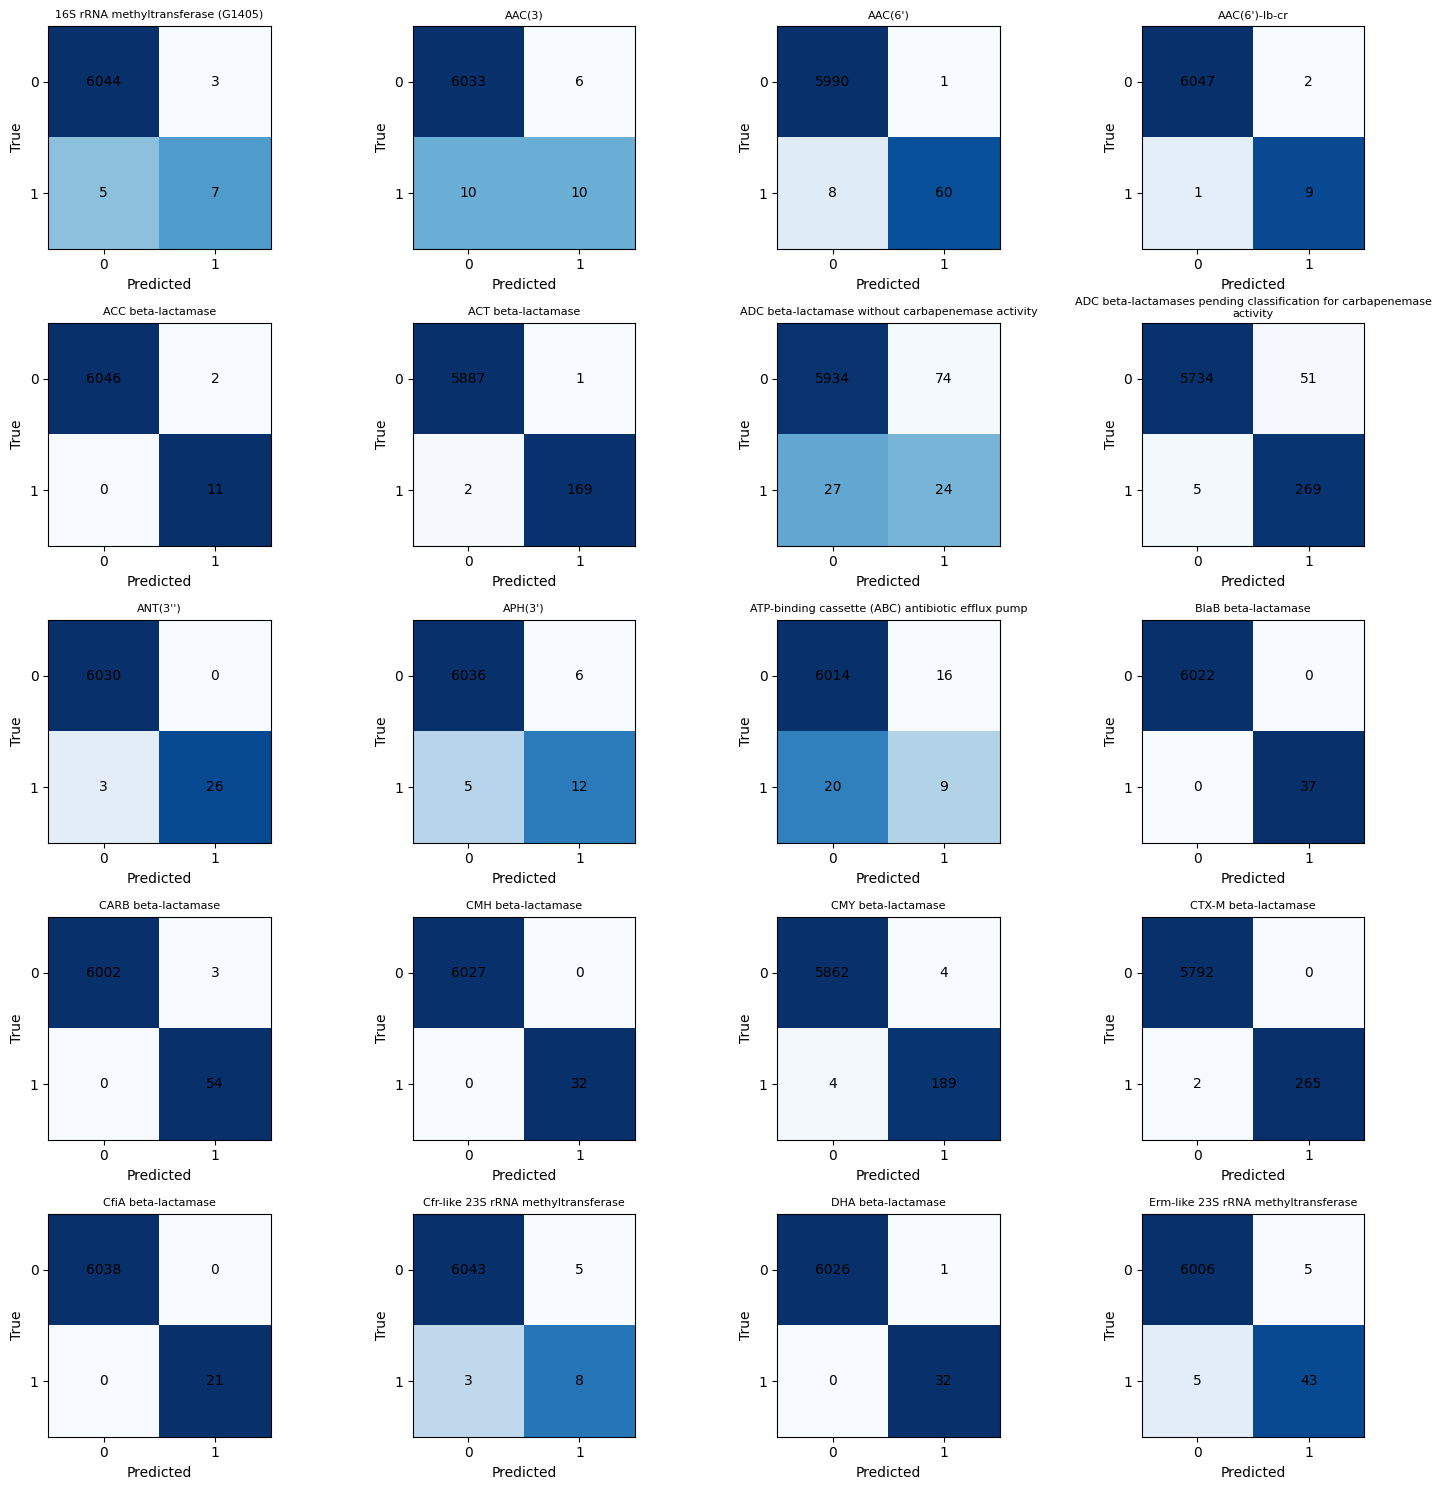

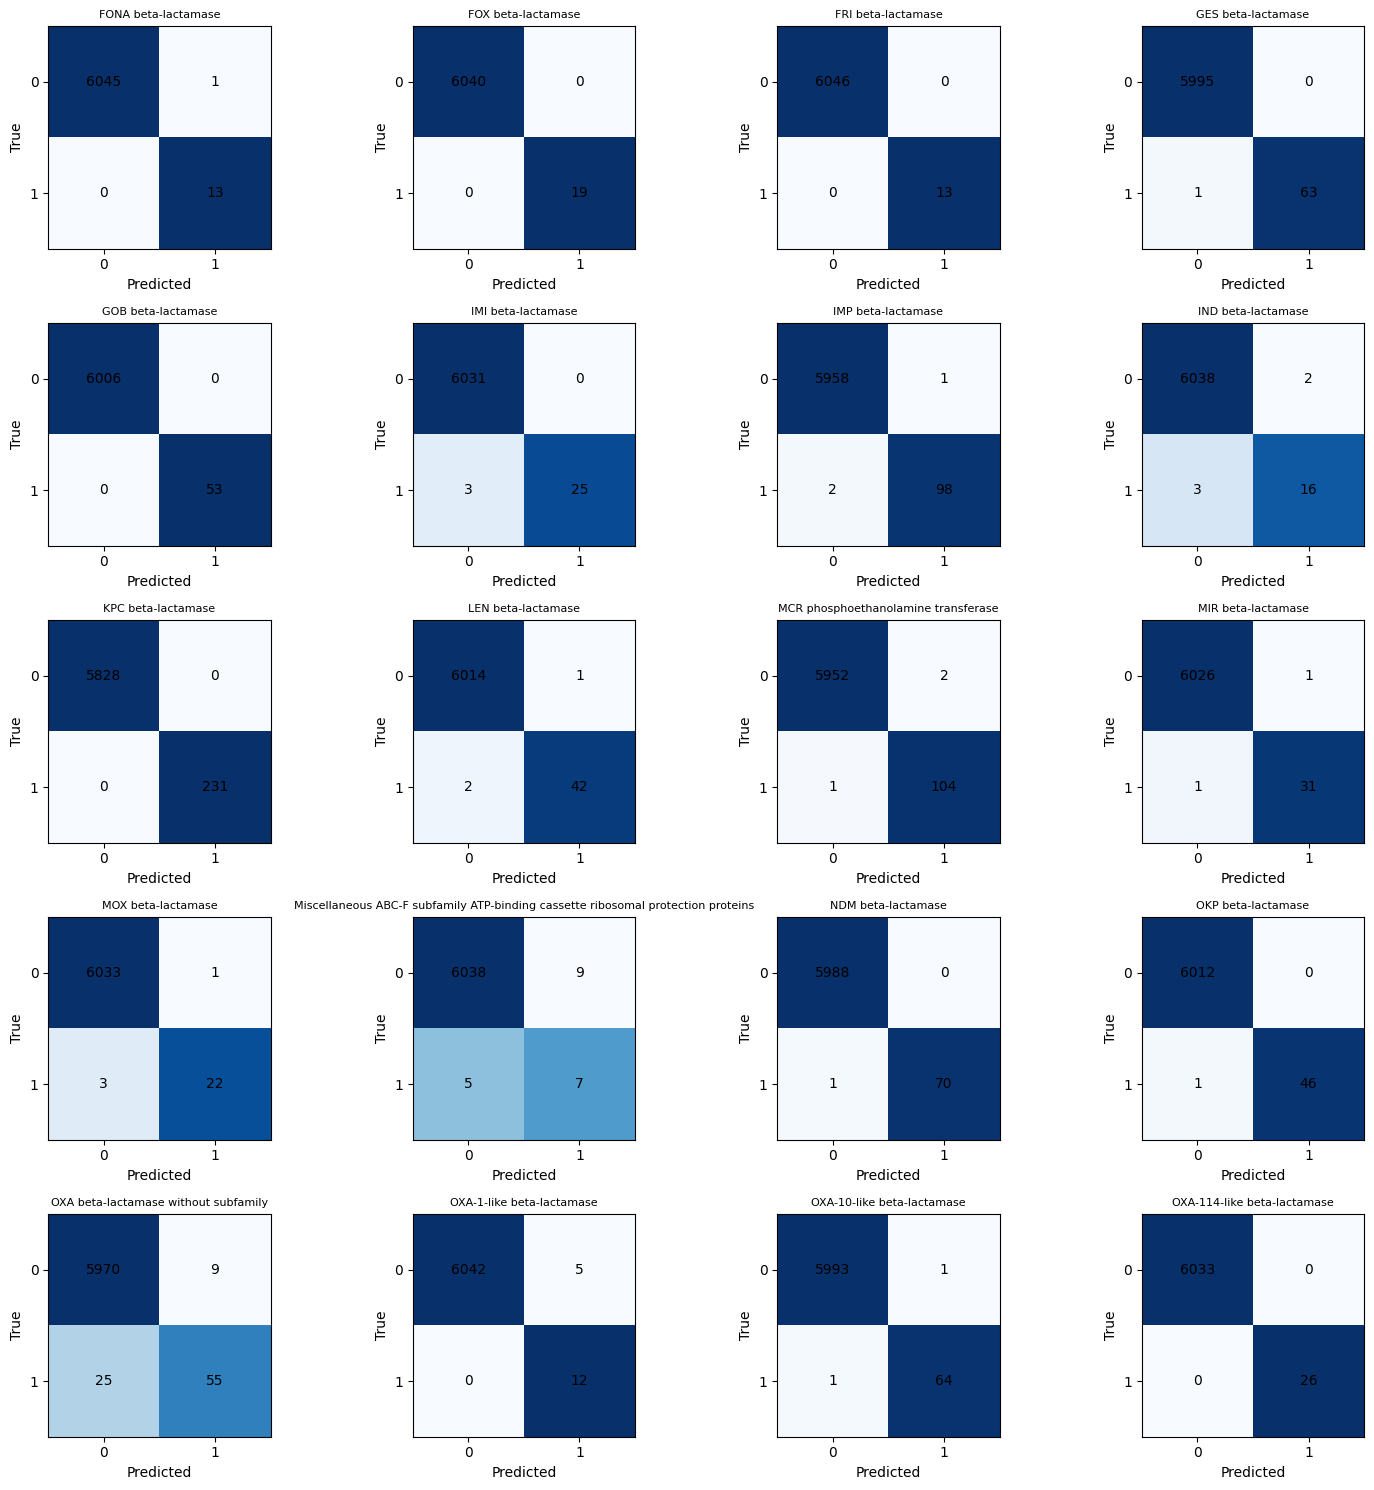

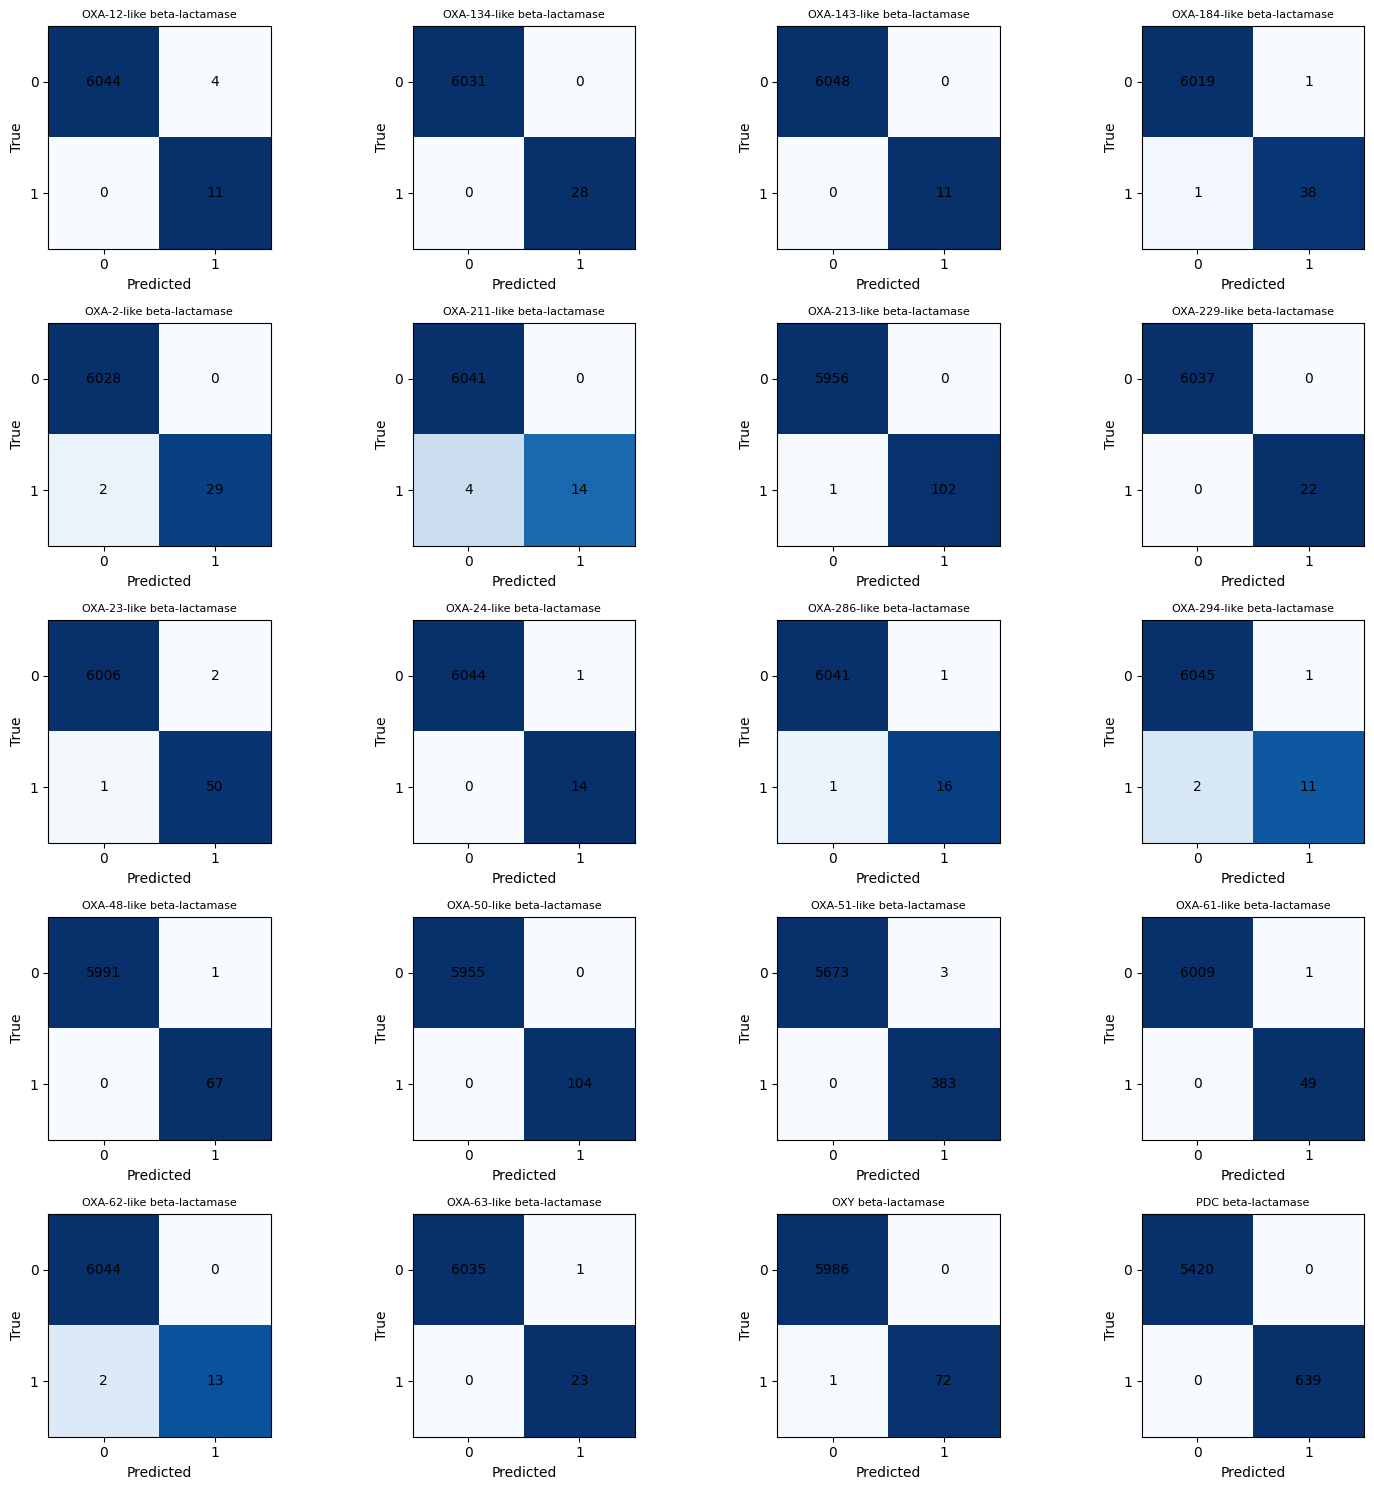

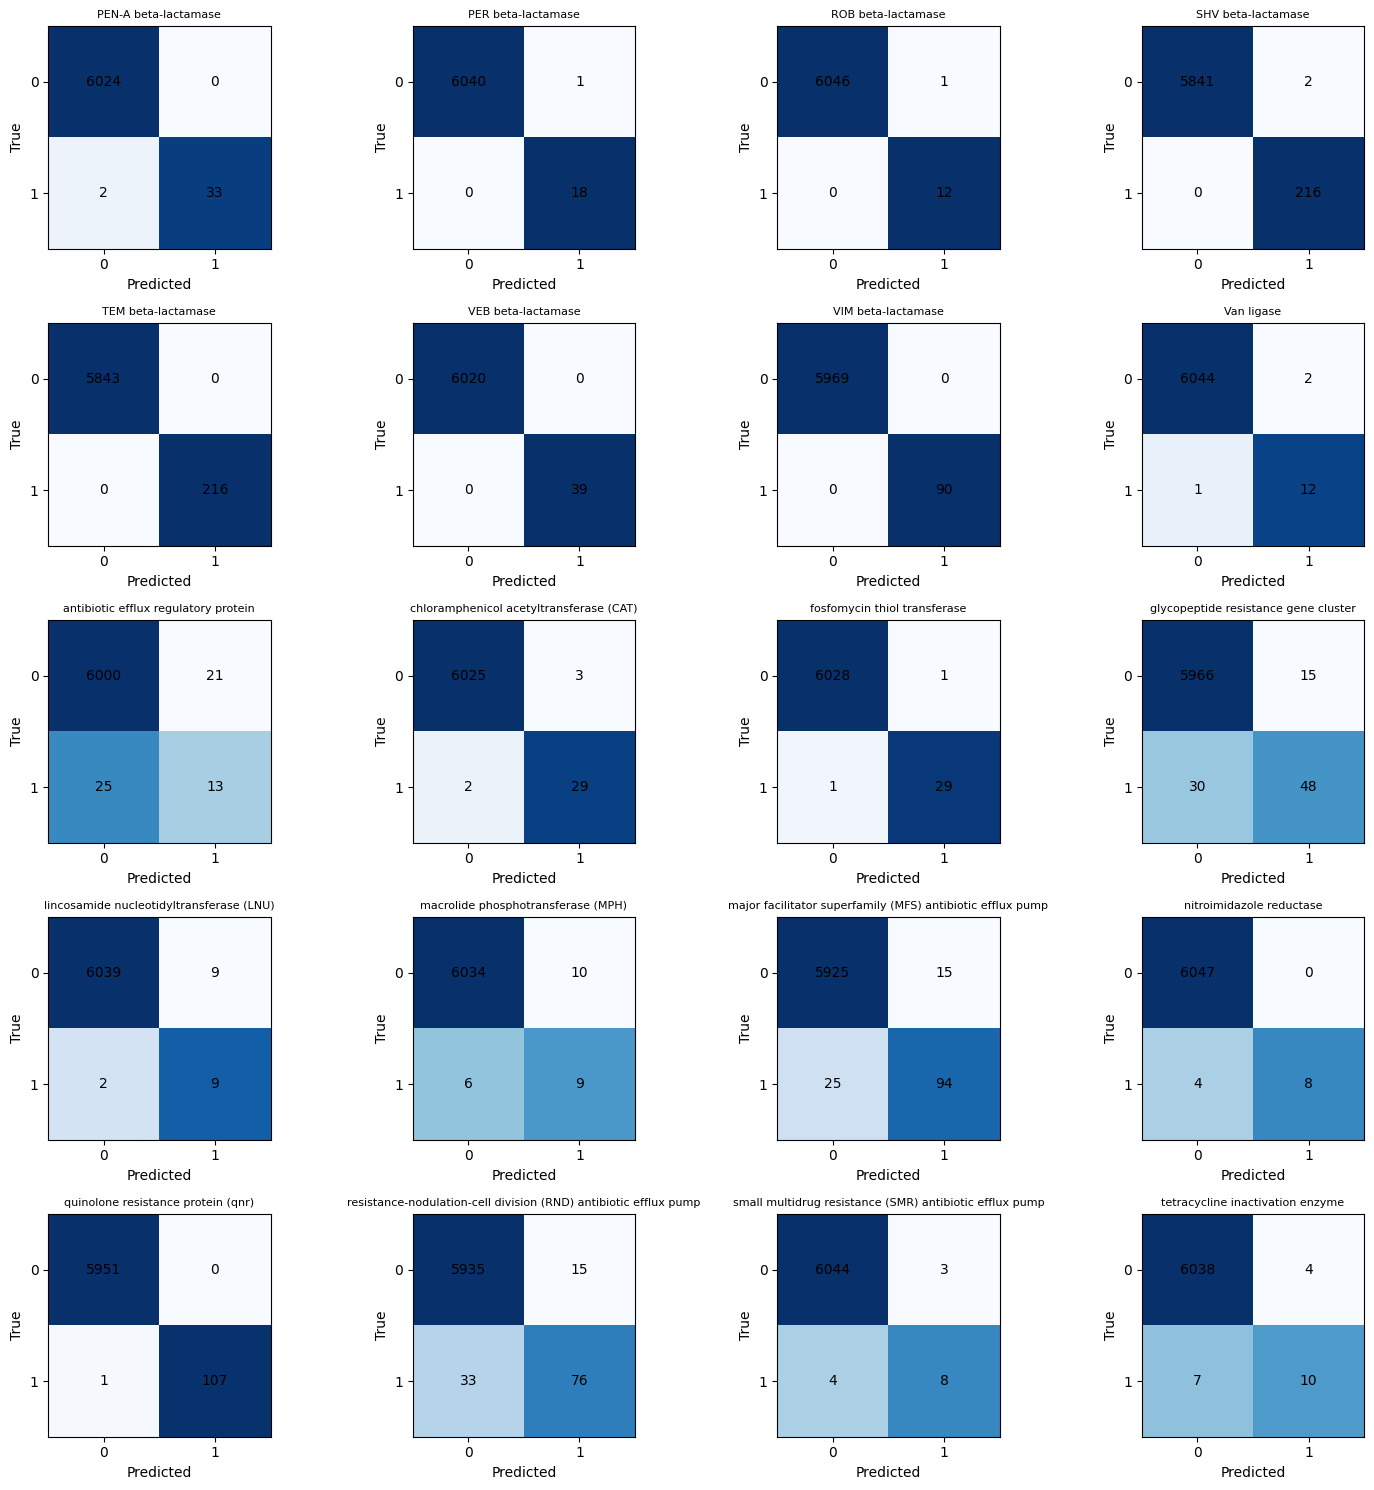

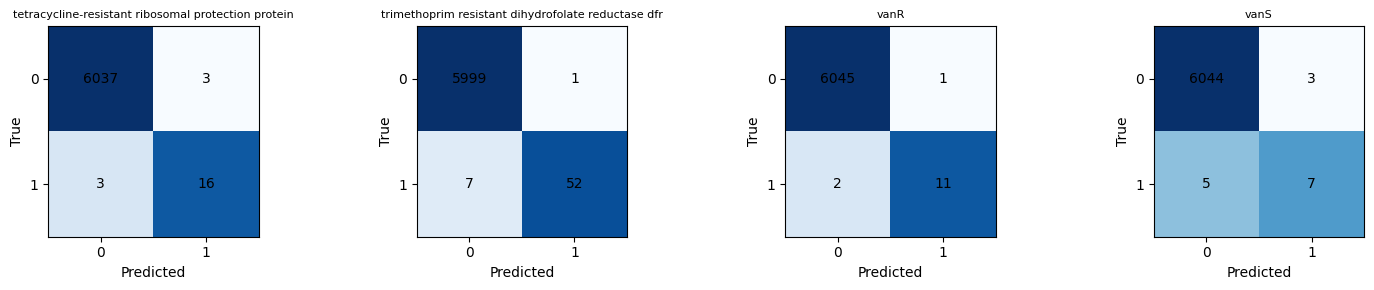

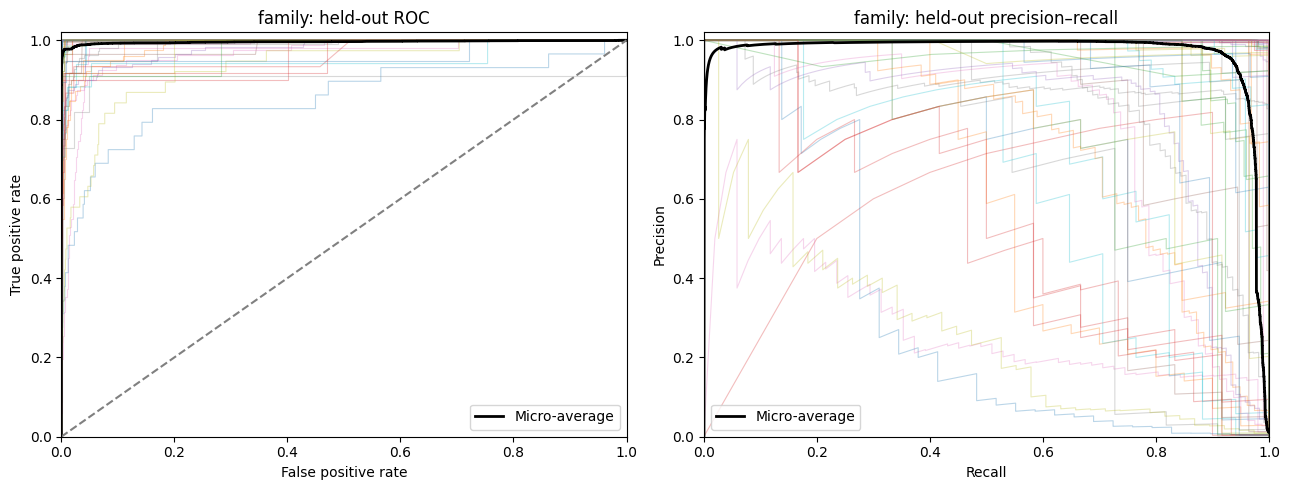

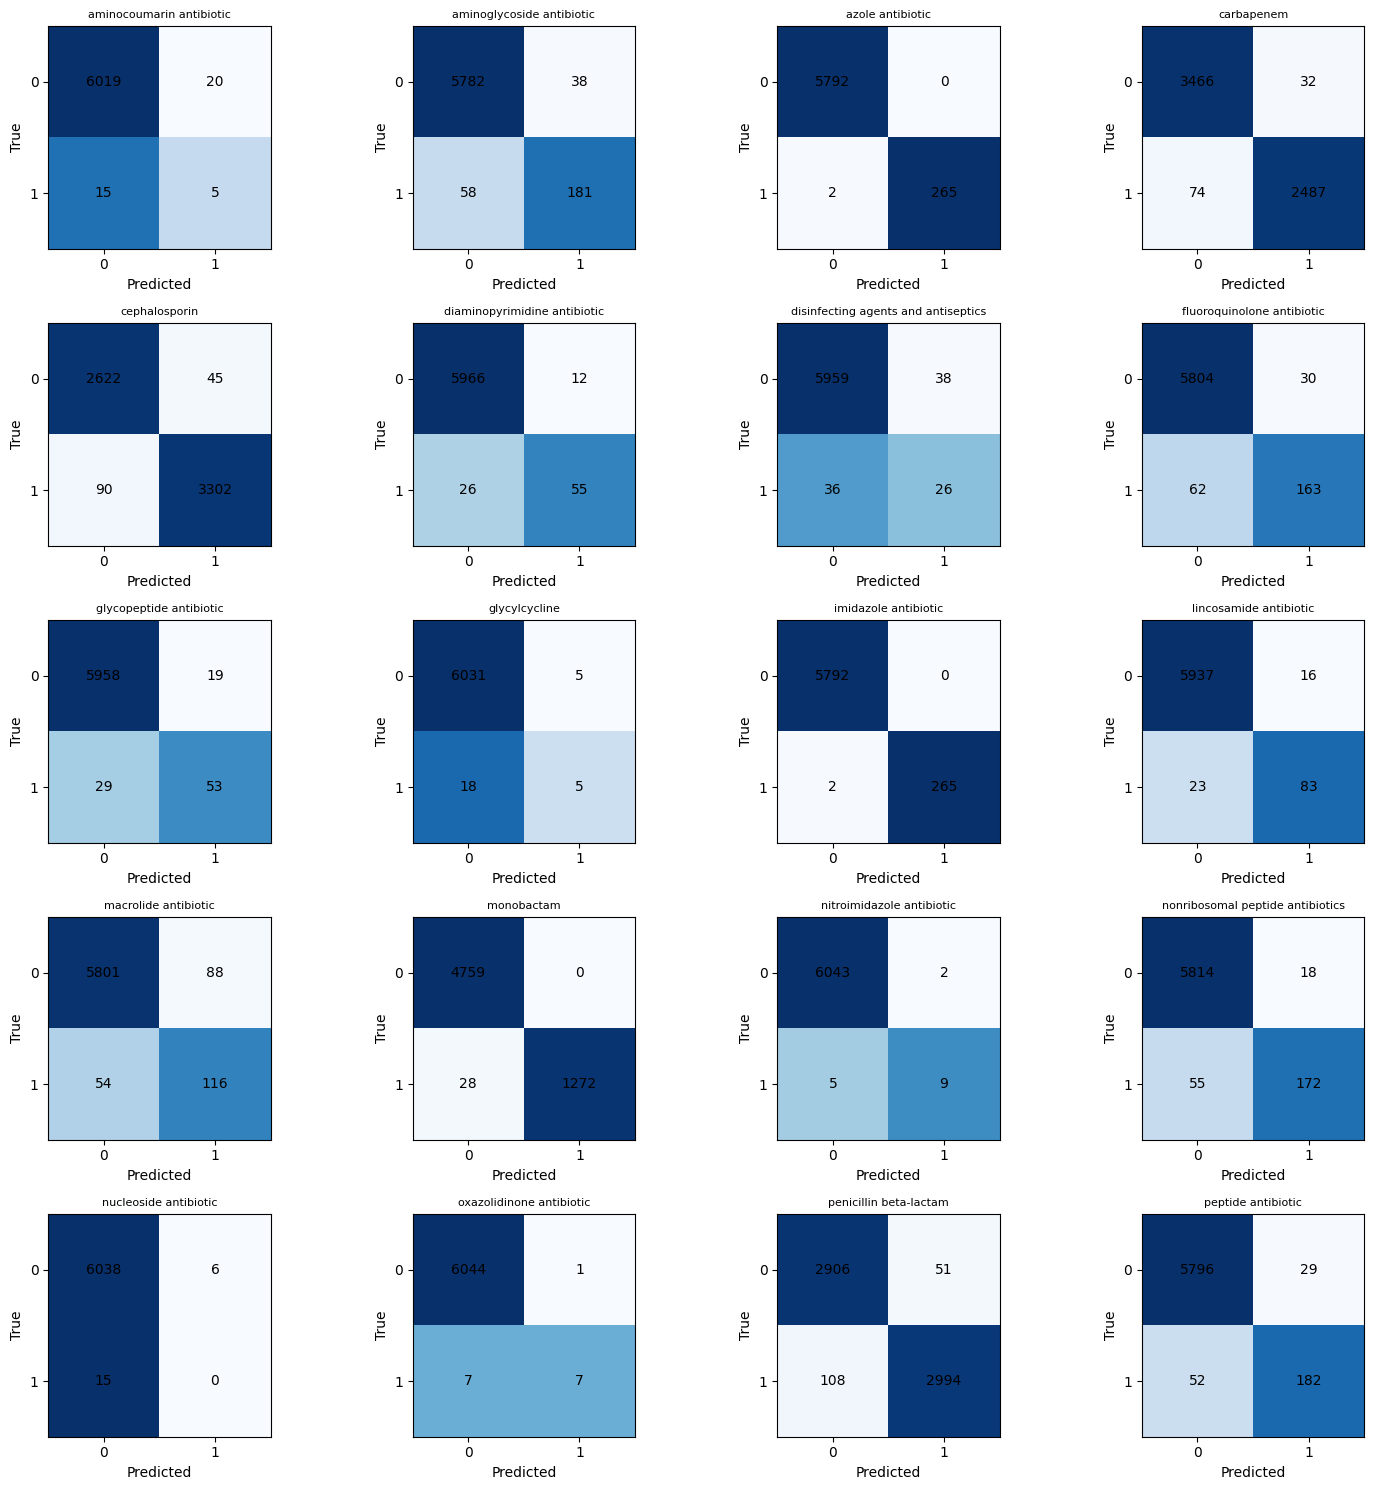

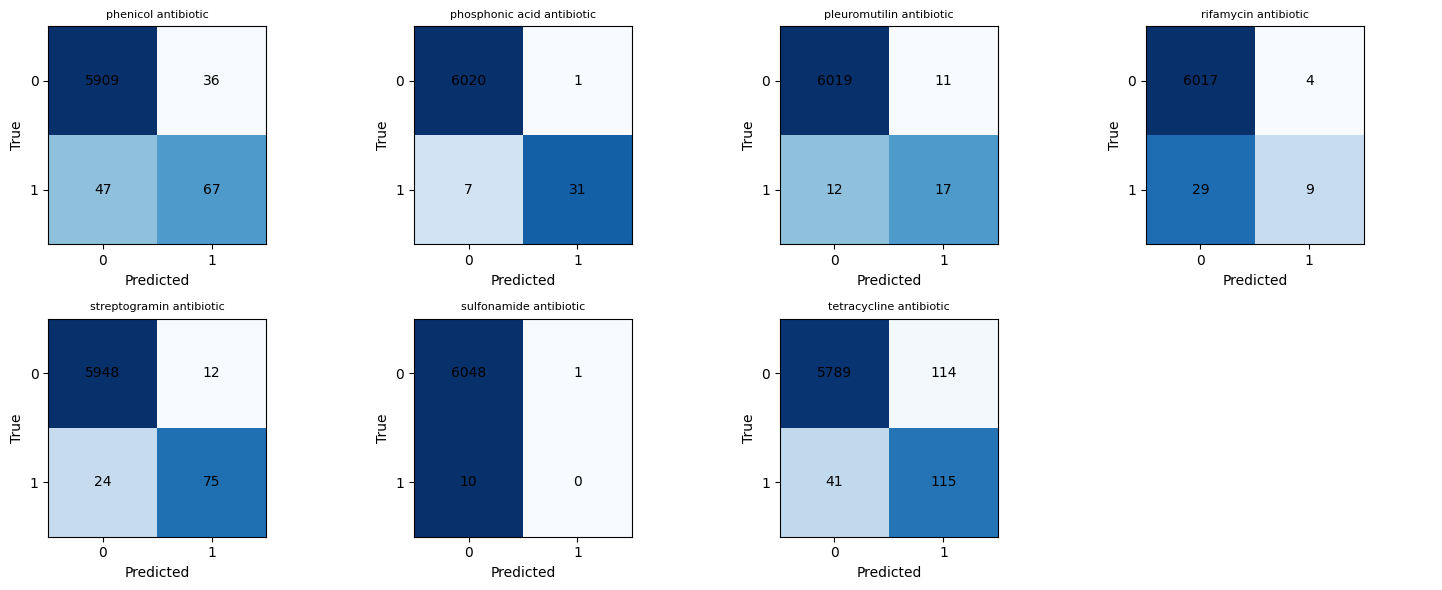

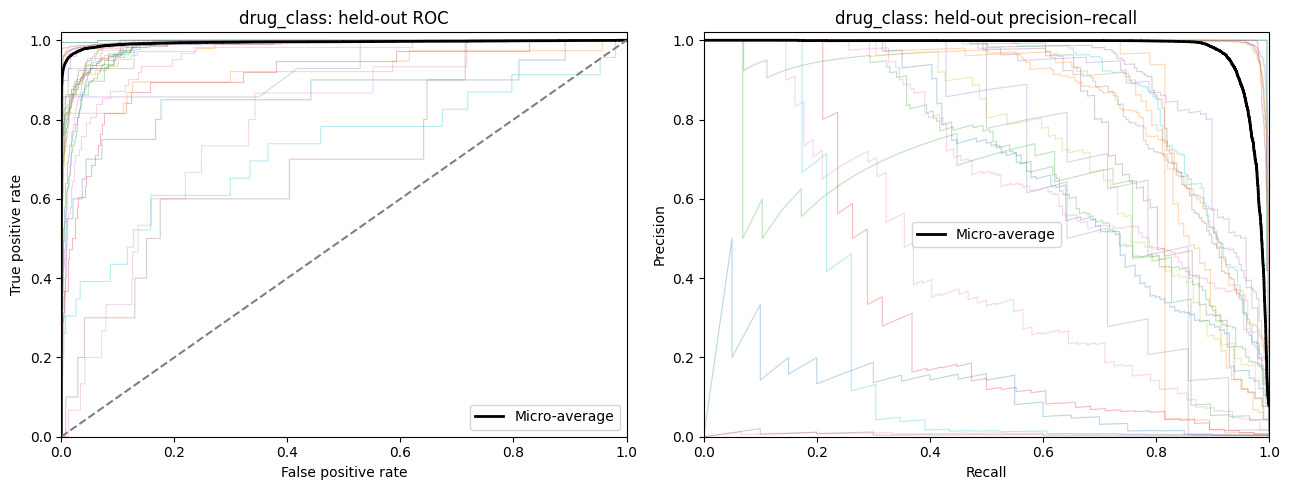

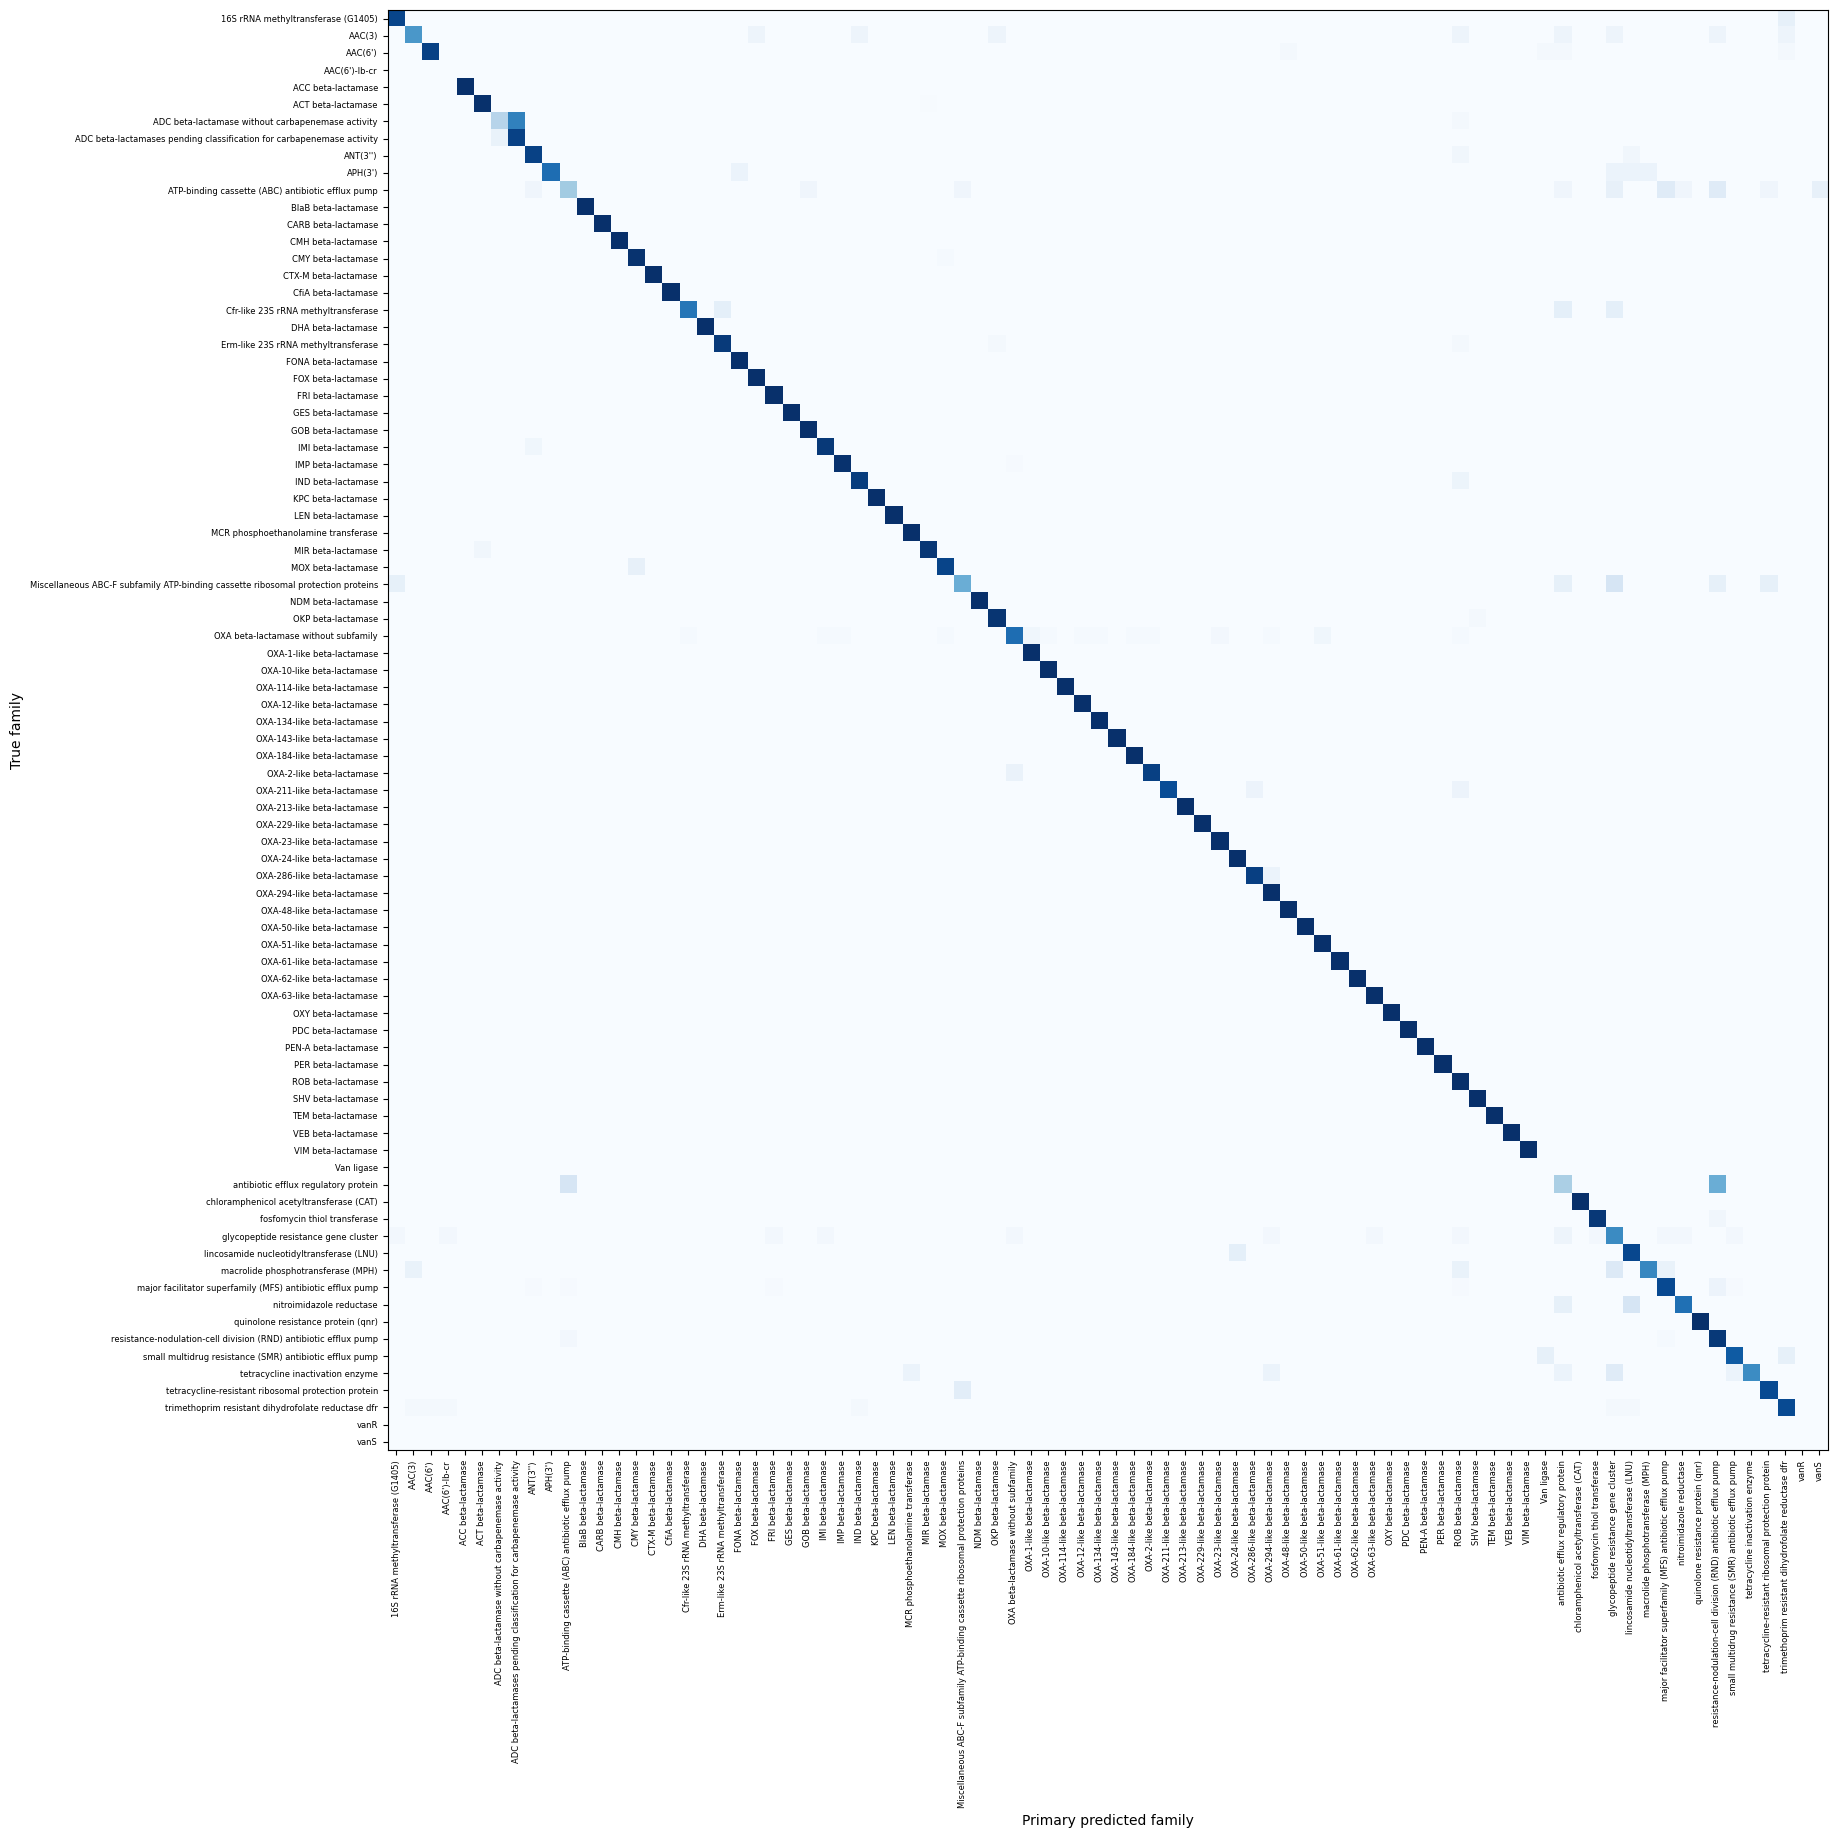

In [10]:
for kind in ("family", "drug_class"):
    indices = [j for j,(k,_) in enumerate(targets) if k == kind]
    for page, start in enumerate(range(0,len(indices),20), 1):
        subset = indices[start:start+20]
        fig, axes = plt.subplots(math.ceil(len(subset)/4),4, figsize=(15,3*math.ceil(len(subset)/4)), squeeze=False)
        for ax,j in zip(axes.flat,subset):
            cm = confusion_matrix(Y[:,j],oof_decisions[:,j],labels=[0,1])
            norm = cm / np.maximum(cm.sum(axis=1,keepdims=True),1)
            ax.imshow(norm,cmap="Blues",vmin=0,vmax=1)
            for a in range(2):
                for b in range(2): ax.text(b,a,str(cm[a,b]),ha="center",va="center")
            ax.set(xticks=[0,1],yticks=[0,1],xlabel="Predicted",ylabel="True")
            ax.set_title(targets[j][1], fontsize=8, wrap=True)
        for ax in list(axes.flat)[len(subset):]: ax.axis("off")
        save_figure(fig, f"{kind}_binary_confusion_page_{page}")
    fig, axes = plt.subplots(1,2,figsize=(13,5))
    for j in indices:
        fpr,tpr,_ = roc_curve(Y[:,j],oof_scores[:,j])
        precision,recall,_ = precision_recall_curve(Y[:,j],oof_scores[:,j])
        axes[0].plot(fpr,tpr,alpha=.30,lw=.8)
        axes[1].plot(recall,precision,alpha=.30,lw=.8)
    fpr,tpr,_=roc_curve(Y[:,indices].ravel(),oof_scores[:,indices].ravel())
    precision,recall,_=precision_recall_curve(Y[:,indices].ravel(),oof_scores[:,indices].ravel())
    axes[0].plot(fpr,tpr,color="black",lw=2,label="Micro-average")
    axes[0].plot([0,1],[0,1],"--",color="grey")
    axes[1].plot(recall,precision,color="black",lw=2,label="Micro-average")
    axes[0].set(xlabel="False positive rate",ylabel="True positive rate",title=f"{kind}: held-out ROC")
    axes[1].set(xlabel="Recall",ylabel="Precision",title=f"{kind}: held-out precision–recall")
    for ax in axes: ax.legend(); ax.set_xlim(0,1); ax.set_ylim(0,1.02)
    save_figure(fig,f"{kind}_roc_pr")
family_indices = [j for j,(k,_) in enumerate(targets) if k == "family"]
family_names = [targets[j][1] for j in family_indices]
single = Y[:,family_indices].sum(axis=1) == 1
truth = Y[single][:,family_indices].argmax(axis=1)
predicted = oof_scores[single][:,family_indices].argmax(axis=1)
family_cm = confusion_matrix(truth,predicted,labels=np.arange(len(family_names)))
pd.DataFrame(family_cm,index=family_names,columns=family_names).to_csv(OUTPUT_DIR / "primary_family_confusion_matrix.csv",index_label="true_family")
(OUTPUT_DIR / "primary_family_metrics.json").write_text(json.dumps(dict(
    n_evaluated=int(single.sum()), n_excluded=int((~single).sum()),
    accuracy=float(accuracy_score(truth,predicted)) if single.any() else None),indent=2))
fig,ax=plt.subplots(figsize=(max(12,len(family_names)*.22),max(10,len(family_names)*.22)))
ax.imshow(family_cm/np.maximum(family_cm.sum(axis=1,keepdims=True),1),cmap="Blues",vmin=0,vmax=1)
ax.set(xticks=np.arange(len(family_names)),yticks=np.arange(len(family_names)),
       xticklabels=family_names,yticklabels=family_names,xlabel="Primary predicted family",ylabel="True family")
plt.setp(ax.get_xticklabels(),rotation=90,fontsize=6)
plt.setp(ax.get_yticklabels(),fontsize=6)
save_figure(fig,"primary_family_confusion_matrix")

## 5. Complete SHAP profiles and the requested cutoff

For target label $c$ and descriptor $j$, $I_{cj}=N^{-1}\sum_i|\phi_{icj}|$ over all outer-held-out proteins. The CSV matrix cells are these **mean absolute SHAP values**, not feature values or correlations. Label eligibility is $\max_j I_{cj}\leq2.0$. Individual local SHAP values may exceed 2; this cutoff is applied to the aggregated global profile only.

Full profiles include all descriptors, including measured zeros. Top-feature sets include up to 15 **strictly positive** importances, ordered by importance then feature name for deterministic ties. A zero-only model has an empty top set rather than arbitrary zero-ranked descriptors. Full-profile Spearman is undefined for constant profiles and is left missing.

In [11]:
if importance.shape != (len(targets),len(feature_names)) or not np.isfinite(importance).all() or (importance < 0).any():
    raise AssertionError("Invalid complete SHAP matrix")
safety = metrics[["target_type","label","ap","f1","weak_model"]].copy()
safety["max_mean_abs_shap"] = importance.max(axis=1)
safety["passes_shap_filter"] = safety["max_mean_abs_shap"] <= SHAP_SAFETY_THRESHOLD
safety["nonzero_features"] = (importance > 0).sum(axis=1)
safety.to_csv(OUTPUT_DIR / "shap_safety_summary.csv", index=False)
full_rows, top_rows = [], []
for j,(kind,label) in enumerate(targets):
    order = sorted(range(len(feature_names)),key=lambda q:(-importance[j,q],feature_names[q]))
    positive = [q for q in order if importance[j,q] > 0][:TOP_N_FEATURES]
    for q in range(len(feature_names)):
        full_rows.append(dict(target_type=kind,label=label,feature=feature_names[q],
                              shap_importance=importance[j,q],feature_source=feature_sources[feature_names[q]]))
    for rank,q in enumerate(positive,1):
        top_rows.append(dict(target_type=kind,label=label,feature=feature_names[q],
            shap_importance=importance[j,q],rank=rank,feature_source=feature_sources[feature_names[q]],
            passes_shap_filter=bool(safety.iloc[j]["passes_shap_filter"])))
full_shap = pd.DataFrame(full_rows)
top_shap = pd.DataFrame(top_rows,columns=["target_type","label","feature","shap_importance","rank","feature_source","passes_shap_filter"])
full_shap.to_csv(OUTPUT_DIR / "all_targets_shap_importance_full.csv",index=False)
top_shap.to_csv(OUTPUT_DIR / "all_targets_top_features_shap.csv",index=False)
top_shap.loc[top_shap["passes_shap_filter"]].to_csv(OUTPUT_DIR / "all_targets_top_features_shap_safe.csv",index=False)
profiles = {}
for kind in ("family","drug_class"):
    idx=[j for j,(k,_) in enumerate(targets) if k==kind]
    profiles[kind] = pd.DataFrame(importance[idx],index=[targets[j][1] for j in idx],columns=feature_names)
    profiles[kind].to_csv(OUTPUT_DIR / f"{kind}_shap_profiles_full.csv",index_label=kind)
    safe_labels=safety.loc[(safety.target_type==kind)&safety.passes_shap_filter,"label"]
    profiles[kind].loc[safe_labels].to_csv(OUTPUT_DIR / f"{kind}_shap_profiles_safe.csv",index_label=kind)
fold_shap_rows=[]
for j,(kind,label) in enumerate(targets):
    for fold in range(len(folds)):
        fold_shap_rows.append(pd.DataFrame(dict(target_type=kind,label=label,fold=fold,
            feature=feature_names,mean_abs_shap=cv_results[j]["fold_importance"][fold],n_explained=len(folds[fold][1]))))
pd.concat(fold_shap_rows,ignore_index=True).to_csv(OUTPUT_DIR / "fold_shap_importance.csv",index=False)
display(safety.groupby(["target_type","passes_shap_filter"]).size().rename("labels"))

target_type  passes_shap_filter
drug_class   True                  27
family       True                  84
Name: labels, dtype: int64

## 6. All family–drug-class pairs: Jaccard, Spearman and CARD links

Every supported family–drug-class pair appears in the pair table. Similarities are calculated only when **both** labels pass the SHAP cutoff; excluded pairs retain their reason and missing scores. Weak models are kept and flagged separately.

Jaccard compares top-feature sets: intersection size / union size. Spearman compares the ranks of all 996 aligned importances, preserving measured zeros. These are descriptive model-profile similarities: shared descriptors do not prove a shared mechanism. Raw magnitudes can differ with label prevalence and fitted model scale even when output units match. CARD linkage means the two annotations co-occur for an ARO in the configured index; a missing link is not proof of biological absence.

In [12]:
def top_feature_map(frame):
    return {(kind,label):group.sort_values("rank").set_index("feature")["rank"].to_dict()
            for (kind,label),group in frame.groupby(["target_type","label"],sort=False)}


def pair_similarity(a, b, a_top, b_top):
    if not a.index.equals(b.index):
        raise ValueError("SHAP profile feature order mismatch")
    shared=sorted(set(a_top)&set(b_top))
    union=set(a_top)|set(b_top)
    jaccard=len(shared)/len(union) if union else np.nan
    spearman=float(spearmanr(a.to_numpy(),b.to_numpy()).statistic) if a.nunique()>1 and b.nunique()>1 else np.nan
    return jaccard,spearman,shared

ranks=top_feature_map(top_shap)
safety_index=safety.set_index(["target_type","label"])
pair_rows=[]
for family,a in profiles["family"].iterrows():
    fs=safety_index.loc[("family",family)]
    for drug,b in profiles["drug_class"].iterrows():
        ds=safety_index.loc[("drug_class",drug)]
        passed=bool(fs.passes_shap_filter and ds.passes_shap_filter)
        ft=ranks.get(("family",family),{})
        dt=ranks.get(("drug_class",drug),{})
        jac,rho,shared=pair_similarity(a,b,ft,dt) if passed else (np.nan,np.nan,[])
        pair_rows.append(dict(family=family,drug_class=drug,card_linked=(family,drug) in card_edges,
            passes_shap_filter=passed,exclusion_reason="" if passed else "one_or_both_labels_exceed_shap_cutoff",
            jaccard=jac,spearman=rho,shared_feature_count=len(shared) if passed else np.nan,
            shared_features=json.dumps(shared) if passed else None,
            shared_feature_ranks=json.dumps({f:{"family_rank":int(ft[f]),"drug_class_rank":int(dt[f])} for f in shared}) if passed else None,
            family_top_count=len(ft),drug_class_top_count=len(dt),
            family_ap=fs.ap,family_f1=fs.f1,drug_class_ap=ds.ap,drug_class_f1=ds.f1,
            family_weak=bool(fs.weak_model),drug_class_weak=bool(ds.weak_model),
            any_weak_model=bool(fs.weak_model or ds.weak_model)))
pairs=pd.DataFrame(pair_rows)
assert len(pairs)==len(profiles["family"])*len(profiles["drug_class"])
assert pairs.jaccard.dropna().between(0,1).all()
assert pairs.spearman.dropna().between(-1-1e-12,1+1e-12).all()
pairs.to_csv(OUTPUT_DIR / "family_drug_class_all_pairs.csv",index=False)
for key in ("jaccard","spearman"):
    matrix=pairs.pivot(index="family",columns="drug_class",values=key)
    matrix.to_csv(OUTPUT_DIR / f"family_drug_class_{key}_matrix.csv",index_label="family")
for linked in (True,False):
    ranked=pairs.loc[pairs.passes_shap_filter & pairs.card_linked.eq(linked)].sort_values(
        ["jaccard","spearman","family","drug_class"],ascending=[False,False,True,True],na_position="last")
    ranked.to_csv(OUTPUT_DIR / ("ranked_CARD_linked_pairs.csv" if linked else "ranked_CARD_unlinked_pairs.csv"),index=False)
# A binary membership export for independent Jaccard calculations.
membership=pd.DataFrame(0,index=pd.MultiIndex.from_tuples(targets,names=["target_type","label"]),columns=feature_names)
for key,feature_ranks in ranks.items():
    membership.loc[key,list(feature_ranks)]=1
membership.to_csv(OUTPUT_DIR / "top_feature_membership.csv")
# Existing family results are top-15 only: use set overlap, never zero-fill for a full correlation.
legacy_rows=[]
if LEGACY_FAMILY_SHAP_CSV.exists():
    legacy=pd.read_csv(LEGACY_FAMILY_SHAP_CSV)
    if not {"family","feature","shap_importance"}.issubset(legacy):
        raise ValueError("Unexpected legacy family SHAP schema")
    for family,group in legacy.groupby("family"):
        if family not in profiles["family"].index: continue
        observed=set(group.feature)&set(feature_names)
        current=set(ranks.get(("family",family),{}))
        union=observed|current
        legacy_rows.append(dict(family=family,legacy_max_shap=float(group.shap_importance.max()),
            legacy_passes_shap_filter=bool(group.shap_importance.max()<=SHAP_SAFETY_THRESHOLD),
            current_passes_shap_filter=bool(safety_index.loc[("family",family),"passes_shap_filter"]),
            legacy_top_features_retained=len(observed),current_top_features=len(current),
            top_set_jaccard=len(observed&current)/len(union) if union else np.nan,
            shared_features=json.dumps(sorted(observed&current))))
else:
    print(f"Optional legacy family comparison skipped: {LEGACY_FAMILY_SHAP_CSV}")
pd.DataFrame(legacy_rows).to_csv(OUTPUT_DIR / "legacy_family_top_feature_comparison.csv",index=False)
display(pairs.loc[pairs.passes_shap_filter].sort_values(["jaccard","spearman"],ascending=False).head(20))

,family,drug_class,card_linked,passes_shap_filter,exclusion_reason,jaccard,spearman,shared_feature_count,shared_features,shared_feature_ranks,family_top_count,drug_class_top_count,family_ap,family_f1,drug_class_ap,drug_class_f1,family_weak,drug_class_weak,any_weak_model
407,CTX-M beta-lactamase,azole antibiotic,True,True,,1.000000,1.000000,15,"[""ATC_C"", ""CTC_212"", ""CTC_345"", ""DDR_W"", ""DPC1...","{""ATC_C"": {""family_rank"": 2, ""drug_class_rank""...",15,15,0.997827,0.996241,0.997827,0.996241,False,False,False
415,CTX-M beta-lactamase,imidazole antibiotic,True,True,,1.000000,1.000000,15,"[""ATC_C"", ""CTC_212"", ""CTC_345"", ""DDR_W"", ""DPC1...","{""ATC_C"": {""family_rank"": 2, ""drug_class_rank""...",15,15,0.997827,0.996241,0.997827,0.996241,False,False,False
1925,glycopeptide resistance gene cluster,glycopeptide antibiotic,True,True,,0.428571,0.790202,9,"[""CTC_421"", ""DDR_C"", ""DDR_Y"", ""DPC1_AF"", ""DPC1...","{""CTC_421"": {""family_rank"": 8, ""drug_class_ran...",15,15,0.749774,0.680851,0.752167,0.688312,False,False,False
2086,resistance-nodulation-cell division (RND) anti...,fluoroquinolone antibiotic,True,True,,0.304348,0.548574,7,"[""DDR_W"", ""DPC1_AQ"", ""DPC1_GW"", ""DPC1_MK"", ""DP...","{""DDR_W"": {""family_rank"": 7, ""drug_class_rank""...",15,15,0.865809,0.760000,0.879418,0.779904,False,False,False
1932,glycopeptide resistance gene cluster,nonribosomal peptide antibiotics,True,True,,0.200000,0.651447,5,"[""DDR_C"", ""DDR_Y"", ""DPC1_GP"", ""DPC1_NT"", ""DPC1...","{""DDR_C"": {""family_rank"": 3, ""drug_class_rank""...",15,15,0.749774,0.680851,0.888801,0.824940,False,False,False
2039,nitroimidazole reductase,nitroimidazole antibiotic,True,True,,0.200000,0.368378,5,"[""CTC_311"", ""DPC1_FH"", ""DPC1_FR"", ""DPC1_MR"", ""...","{""CTC_311"": {""family_rank"": 2, ""drug_class_ran...",15,15,0.770409,0.800000,0.745207,0.720000,False,False,False
1936,glycopeptide resistance gene cluster,peptide antibiotic,True,True,,0.153846,0.638652,4,"[""DDR_Y"", ""DPC1_AM"", ""DPC1_GP"", ""DPC1_WP""]","{""DDR_Y"": {""family_rank"": 2, ""drug_class_rank""...",15,15,0.749774,0.680851,0.889352,0.817978,False,False,False
990,OXA beta-lactamase without subfamily,penicillin beta-lactam,True,True,,0.153846,0.608851,4,"[""DPC1_DN"", ""DPC1_GN"", ""DPC1_GW"", ""DPC1_TG""]","{""DPC1_DN"": {""family_rank"": 3, ""drug_class_ran...",15,15,0.774731,0.763889,0.996227,0.974134,False,False,False
2105,resistance-nodulation-cell division (RND) anti...,tetracycline antibiotic,True,True,,0.153846,0.524705,4,"[""DPC1_ST"", ""DPC1_WP"", ""M_aliphatic_index"", ""P...","{""DPC1_ST"": {""family_rank"": 8, ""drug_class_ran...",15,15,0.865809,0.760000,0.710373,0.597403,False,False,False
1843,antibiotic efflux regulatory protein,fluoroquinolone antibiotic,True,True,,0.153846,0.493052,4,"[""CTC_665"", ""DPC1_AQ"", ""M_aliphatic_index"", ""P...","{""CTC_665"": {""family_rank"": 5, ""drug_class_ran...",15,15,0.274934,0.361111,0.879418,0.779904,True,False,True


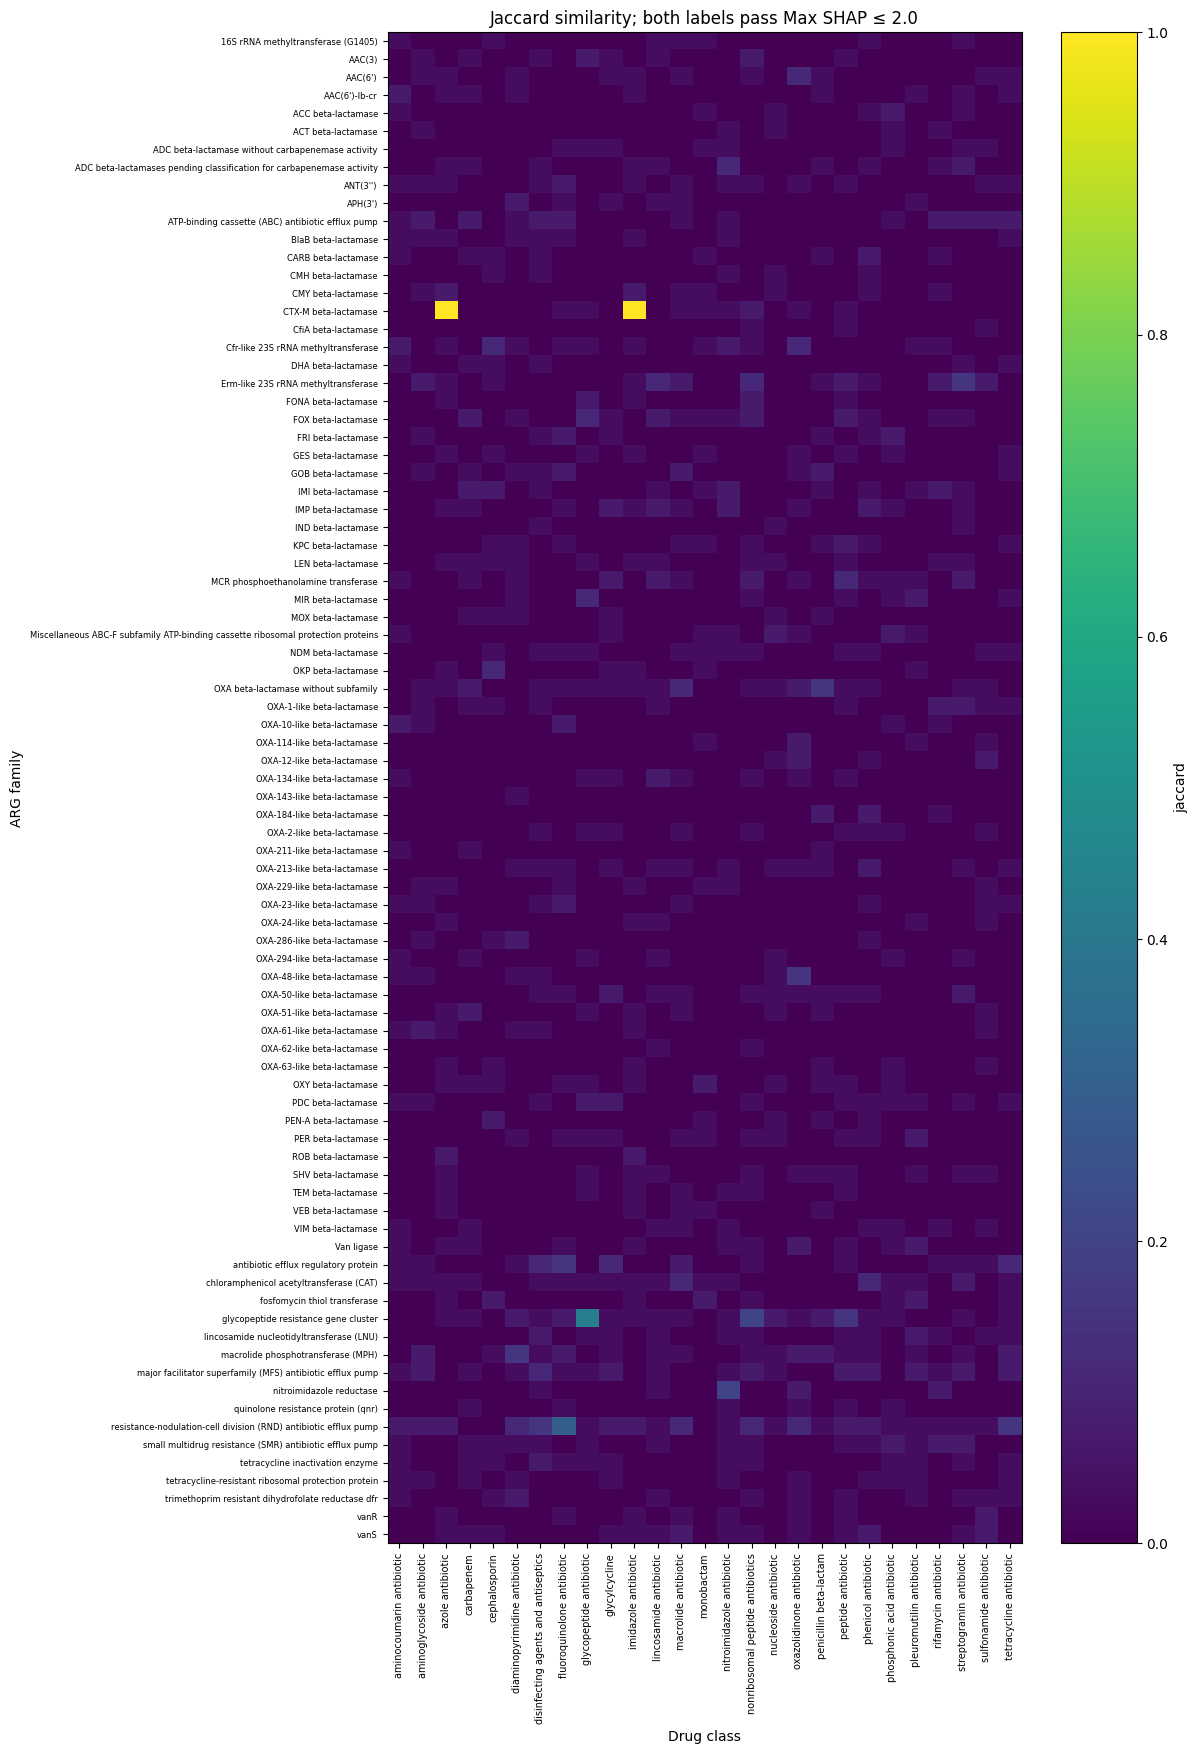

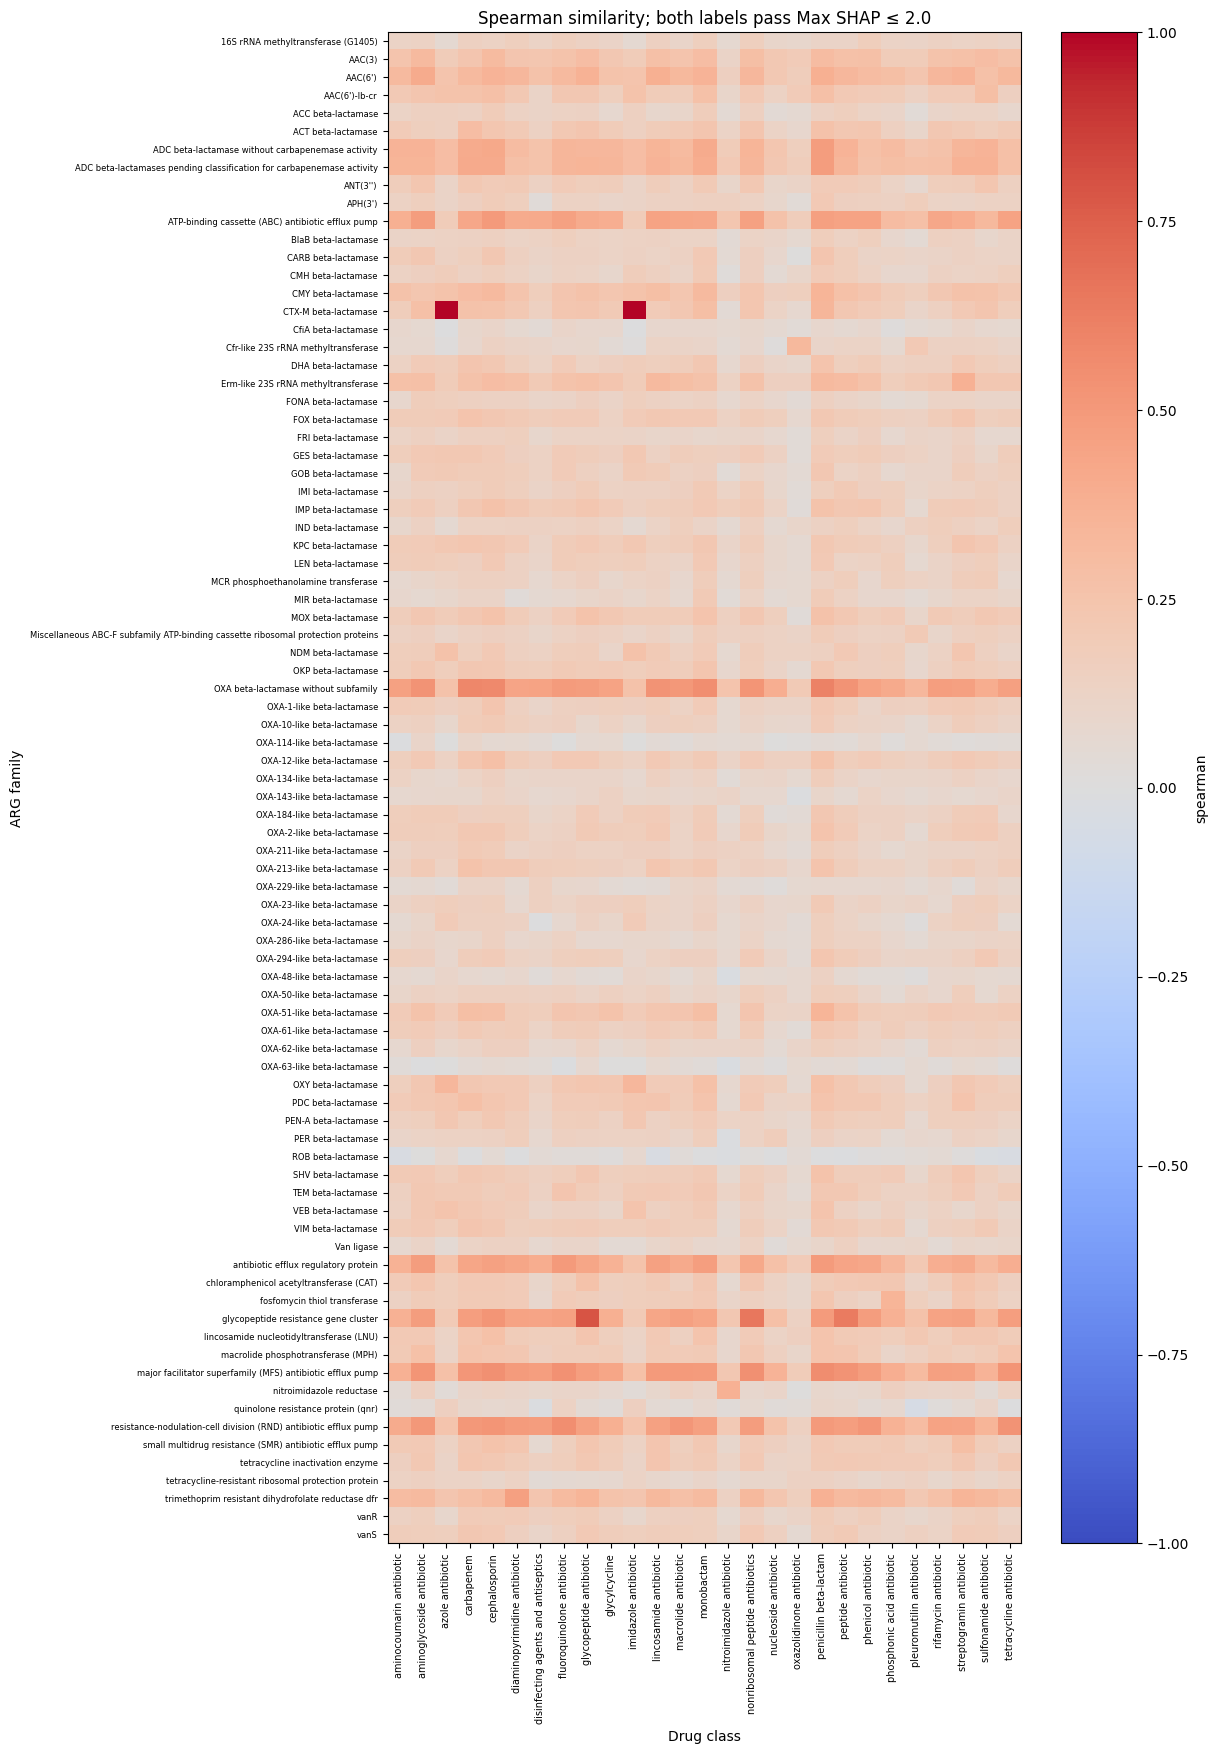

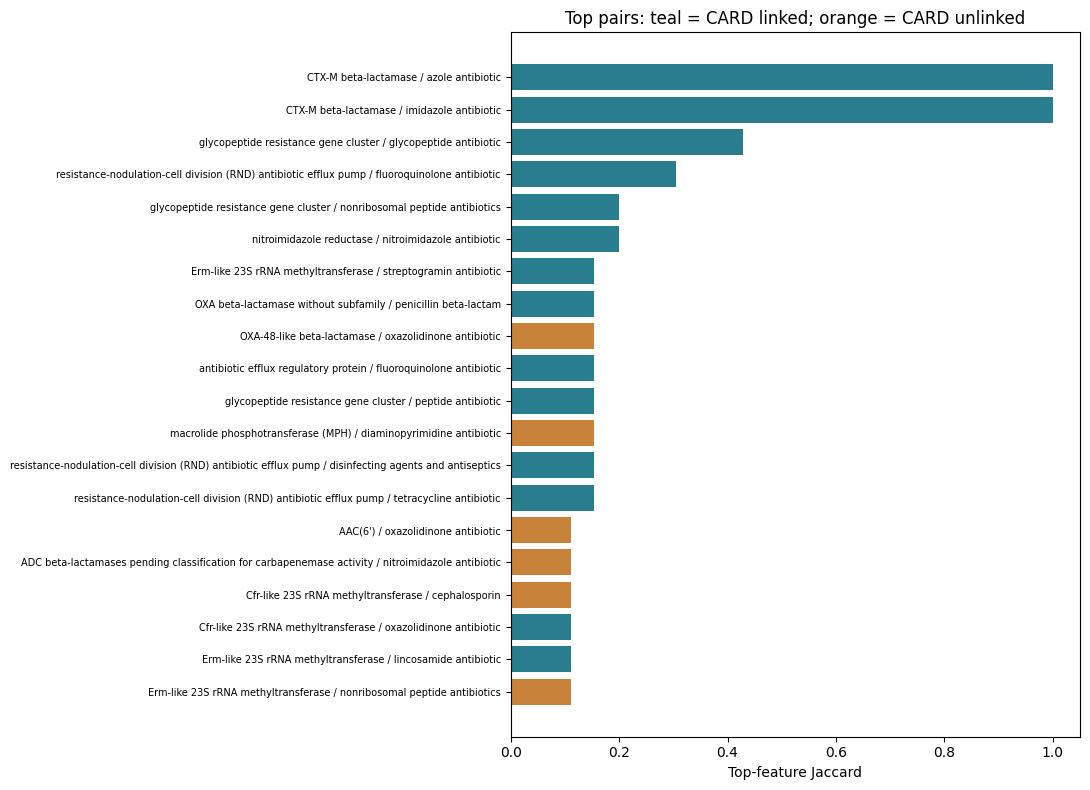

In [13]:
for key in ("jaccard","spearman"):
    matrix=pairs.loc[pairs.passes_shap_filter].pivot(index="family",columns="drug_class",values=key)
    if matrix.empty:
        print(f"No pairs pass the SHAP cutoff; {key} heatmap skipped")
        continue
    fig,ax=plt.subplots(figsize=(max(12,len(matrix.columns)*.42),max(8,len(matrix)*.21)))
    cmap=plt.get_cmap("viridis" if key=="jaccard" else "coolwarm").copy()
    cmap.set_bad("lightgrey")
    im=ax.imshow(np.ma.masked_invalid(matrix.to_numpy()),aspect="auto",cmap=cmap,
                 vmin=0 if key=="jaccard" else -1,vmax=1)
    ax.set(xticks=np.arange(len(matrix.columns)),yticks=np.arange(len(matrix)),
        xticklabels=matrix.columns,yticklabels=matrix.index,xlabel="Drug class",ylabel="ARG family",
        title=f"{key.capitalize()} similarity; both labels pass Max SHAP ≤ {SHAP_SAFETY_THRESHOLD}")
    plt.setp(ax.get_xticklabels(),rotation=90,fontsize=7)
    plt.setp(ax.get_yticklabels(),fontsize=6)
    fig.colorbar(im,ax=ax,label=key)
    save_figure(fig,f"family_drug_class_{key}_heatmap")
ranked=pairs.loc[pairs.passes_shap_filter & pairs.jaccard.notna()].nlargest(20,"jaccard").iloc[::-1]
if not ranked.empty:
    fig,ax=plt.subplots(figsize=(11,8))
    ax.barh(np.arange(len(ranked)),ranked.jaccard,color=["#287d8e" if x else "#c98239" for x in ranked.card_linked])
    ax.set(yticks=np.arange(len(ranked)),yticklabels=[f"{r.family} / {r.drug_class}" for r in ranked.itertuples()],
        xlabel="Top-feature Jaccard",title="Top pairs: teal = CARD linked; orange = CARD unlinked")
    ax.tick_params(axis="y",labelsize=7)
    save_figure(fig,"top_family_drug_class_pairs")

## 7. Inference helpers — standalone cell

The bundle contains native LightGBM model text, JSON metadata, and numeric NumPy arrays; it does not require pickle/joblib. All constituent predictors and the held-out demonstration models are inside **one ZIP file**. Loading this cell defines helpers without fitting models or running prediction.

The feature applicability check fits median imputation, robust scaling and PCA on the relevant training rows only. It records the 99th percentile of leave-one-out nearest-neighbour distances in PCA space and the 99th percentile of reconstruction residuals in scaled descriptor space. The residual check helps detect differences lost by PCA. These checks are **heuristics**, not calibrated novelty probabilities or a non-ARG detector.

Verdicts are assigned per predicted label: **Out of distribution** takes priority; otherwise **Low confidence** applies when the score is below the stored threshold, AP/F1 is below 0.50, or query features are missing; otherwise **Accepted**. Missing feature columns or infinite values are extraction errors. Multiple supported family assignments are reported; their highest score is the primary family. CARD consistency and exact training-sequence matches are reported separately. An accepted output is a computational candidate among the trained labels.

In [14]:
# INFERENCE HELPERS — can be run in a fresh kernel without training cells.
from pathlib import Path
import hashlib
import io
import json
import zipfile
import numpy as np
import pandas as pd
import lightgbm as lgb
import shap
from sklearn.neighbors import NearestNeighbors


def load_arg_bundle(path, mode="final"):
    if mode not in ("final","heldout_demo"):
        raise ValueError("mode must be final or heldout_demo")
    with zipfile.ZipFile(Path(path)) as archive:
        meta=json.loads(archive.read("metadata.json"))
        if meta.get("schema_version")!=1 or meta.get("task")!="arg_family_drug_class":
            raise ValueError("Unsupported model bundle")
        features=meta["feature_names"]
        specs=meta["targets"]
        if not features or len(set(features))!=len(features) or not specs:
            raise ValueError("Invalid feature/target schema")
        if len({(s["target_type"],s["label"]) for s in specs})!=len(specs):
            raise ValueError("Duplicate targets")
        if {s["target_type"] for s in specs}!={"family","drug_class"}:
            raise ValueError("Both target types are required")
        thresholds=np.asarray([s["threshold"] if mode=="final" else s["demo_threshold"] for s in specs])
        if not np.isfinite(thresholds).all() or not ((thresholds>0)&(thresholds<1)).all():
            raise ValueError("Invalid stored thresholds")
        models=[lgb.Booster(model_str=archive.read(s["model_file"] if mode=="final" else s["demo_model_file"]).decode()) for s in specs]
        with np.load(io.BytesIO(archive.read(f"{mode}/applicability.npz")),allow_pickle=False) as z:
            applicability={k:z[k].copy() for k in z.files}
    if any(m.num_feature()!=len(features) for m in models):
        raise ValueError("Model and feature schema mismatch")
    for s,m in zip(specs,models):
        if m.feature_name()!=meta["booster_feature_names"]:
            raise ValueError(f"Feature order mismatch: {s['label']}")
    n=len(features)
    for key in ("median","center","scale","pca_mean"):
        if applicability[key].shape!=(n,) or not np.isfinite(applicability[key]).all():
            raise ValueError(f"Invalid applicability array: {key}")
    if (applicability["scale"]<=0).any(): raise ValueError("Invalid scaler")
    if applicability["components"].shape[1]!=n or applicability["reference"].shape[1]!=applicability["components"].shape[0]:
        raise ValueError("Invalid PCA reference shape")
    return dict(metadata=meta,models=models,thresholds=thresholds,applicability=applicability,mode=mode)


def prepare_query_features(bundle, frame):
    frame=pd.DataFrame(frame).copy()
    order=bundle["metadata"]["feature_names"]
    if frame.empty or not frame.columns.is_unique:
        raise ValueError("Empty query features or duplicate descriptor columns")
    missing=[f for f in order if f not in frame]
    if missing: raise ValueError(f"Missing required feature columns: {missing[:20]}")
    x=frame.loc[:,order].apply(pd.to_numeric,errors="raise").to_numpy(dtype=float)
    if np.isinf(x).any(): raise ValueError("Infinite descriptor values; inspect extraction")
    if np.isnan(x).all(axis=1).any(): raise ValueError("A query has no usable features")
    return x


def applicability_report(bundle,x):
    a=bundle["applicability"]
    filled=np.where(np.isnan(x),a["median"],x)
    scaled=(filled-a["center"])/a["scale"]
    latent=(scaled-a["pca_mean"])@a["components"].T
    reconstruction=latent@a["components"]+a["pca_mean"]
    residual=np.linalg.norm(scaled-reconstruction,axis=1)/np.sqrt(x.shape[1])
    nn=NearestNeighbors(n_neighbors=1,n_jobs=2).fit(a["reference"])
    distance=nn.kneighbors(latent,return_distance=True)[0][:,0]
    distance_cutoff=float(a["distance_cutoff"].item())
    residual_cutoff=float(a["residual_cutoff"].item())
    return pd.DataFrame(dict(nearest_training_distance=distance,distance_cutoff=distance_cutoff,
        reconstruction_residual=residual,residual_cutoff=residual_cutoff,
        out_of_distribution=(distance>distance_cutoff)|(residual>residual_cutoff),
        missing_feature_count=np.isnan(x).sum(axis=1)))


def evidence_verdict(score,threshold,ap,f1,ood,missing,min_ap,min_f1):
    reasons=[]
    if ood: reasons.append("outside_training_descriptor_distribution")
    if score<threshold: reasons.append("below_label_threshold")
    if not np.isfinite(ap) or ap<min_ap: reasons.append("weak_heldout_average_precision")
    if not np.isfinite(f1) or f1<min_f1: reasons.append("weak_heldout_f1")
    if missing: reasons.append("missing_query_descriptors")
    verdict="Out of distribution" if ood else ("Low confidence" if reasons else "Accepted")
    return verdict,";".join(reasons)


def predict_arg_features(bundle,frame,sequence_records):
    x=prepare_query_features(bundle,frame)
    ids=[r["sequence_id"] for r in sequence_records]
    if len(ids)!=len(x) or len(ids)!=len(set(ids)):
        raise ValueError("Sequence identifiers must be unique and aligned with feature rows")
    if "sequence_id" in frame and frame["sequence_id"].tolist()!=ids:
        raise ValueError("Feature and FASTA row order mismatch")
    meta=bundle["metadata"]
    scores=np.column_stack([m.predict(x,num_threads=2) for m in bundle["models"]])
    if not np.isfinite(scores).all() or ((scores<0)|(scores>1)).any():
        raise ValueError("Invalid model scores")
    applicability=applicability_report(bundle,x)
    hashes=set(meta["training_sequence_hashes"] if bundle["mode"]=="final" else meta["demo_training_sequence_hashes"])
    edges={tuple(pair) for pair in meta["card_edges"]}
    fidx=[j for j,s in enumerate(meta["targets"]) if s["target_type"]=="family"]
    didx=[j for j,s in enumerate(meta["targets"]) if s["target_type"]=="drug_class"]
    rows,summary,pair_rows=[],[],[]
    for i,rec in enumerate(sequence_records):
        status=applicability.iloc[i]
        family_order=sorted(fidx,key=lambda j:(-scores[i,j],meta["targets"][j]["label"]))
        drug_order=sorted(didx,key=lambda j:(-scores[i,j],meta["targets"][j]["label"]))
        primary=family_order[0]
        chosen_drugs=[j for j in drug_order if scores[i,j]>=bundle["thresholds"][j]]
        chosen_families=[j for j in family_order if scores[i,j]>=bundle["thresholds"][j]]
        verdicts={}
        for kind,order in (("family",family_order),("drug_class",drug_order)):
            for rank,j in enumerate(order,1):
                spec=meta["targets"][j]
                verdict,reason=evidence_verdict(scores[i,j],bundle["thresholds"][j],spec["ap"],spec["f1"],
                    bool(status.out_of_distribution),int(status.missing_feature_count),meta["min_reliability_ap"],meta["min_reliability_f1"])
                verdicts[j]=verdict
                rows.append(dict(sequence_id=rec["sequence_id"],target_type=kind,label=spec["label"],rank=rank,
                    score=float(scores[i,j]),threshold=float(bundle["thresholds"][j]),
                    passes_threshold=bool(scores[i,j]>=bundle["thresholds"][j]),
                    n_training_positive=spec["n_positive"] if bundle["mode"]=="final" else spec["demo_n_positive"],
                    heldout_ap=spec["ap"],heldout_f1=spec["f1"],verdict=verdict,reasons=reason))
        family_name=meta["targets"][primary]["label"]
        for j in chosen_drugs:
            drug=meta["targets"][j]["label"]
            pair_rows.append(dict(sequence_id=rec["sequence_id"],family=family_name,drug_class=drug,
                card_linked=(family_name,drug) in edges,family_verdict=verdicts[primary],drug_class_verdict=verdicts[j]))
        seen=rec["sequence_sha256"] in hashes
        overall=("Out of distribution" if status.out_of_distribution else
                 "Accepted" if chosen_drugs and verdicts[primary]=="Accepted" and all(verdicts[j]=="Accepted" for j in chosen_drugs)
                 else "Low confidence")
        summary.append(dict(sequence_id=rec["sequence_id"],primary_family=family_name,
            family_score=float(scores[i,primary]),family_verdict=verdicts[primary],
            families_above_threshold=json.dumps([meta["targets"][j]["label"] for j in chosen_families]),
            multiple_family_assignments=len(chosen_families)>1,
            predicted_drug_classes=json.dumps([meta["targets"][j]["label"] for j in chosen_drugs]),
            accepted_drug_classes=json.dumps([meta["targets"][j]["label"] for j in chosen_drugs if verdicts[j]=="Accepted"]),
            drug_status="assigned" if chosen_drugs else "no_drug_class_above_threshold",overall_verdict=overall,
            exact_training_match=seen,generalization_test_status="seen_in_training" if seen else "not_an_exact_training_match",
            **status.to_dict()))
    return (pd.DataFrame(summary),pd.DataFrame(rows),pd.DataFrame(pair_rows,columns=[
        "sequence_id","family","drug_class","card_linked","family_verdict","drug_class_verdict"]),x)


def explain_query_predictions(bundle,x,records,ranked,top_n=15):
    rows=[]
    for i,record in enumerate(records):
        current=ranked.loc[ranked.sequence_id.eq(record["sequence_id"])]
        selected=current.loc[((current.target_type=="family")&(current["rank"]==1))|
            ((current.target_type=="drug_class")&(current.passes_threshold|(current["rank"]==1)))]
        wanted={(r.target_type,r.label) for r in selected.itertuples()}
        for j,spec in enumerate(bundle["metadata"]["targets"]):
            if (spec["target_type"],spec["label"]) not in wanted: continue
            model=bundle["models"][j]
            exp=shap.TreeExplainer(model,model_output="raw",feature_perturbation="tree_path_dependent",
                feature_names=bundle["metadata"]["feature_names"])(x[i:i+1],check_additivity=True)
            if exp.values.ndim==3 and exp.values.shape[-1]==2: exp=exp[...,1]
            if exp.values.shape!=(1,x.shape[1]) or not np.isfinite(exp.values).all():
                raise ValueError("Invalid local SHAP explanation")
            values=exp.values[0]
            base=float(np.asarray(exp.base_values).reshape(-1)[0])
            raw=float(model.predict(x[i:i+1],raw_score=True,num_threads=2)[0])
            np.testing.assert_allclose(base+values.sum(),raw,rtol=1e-5,atol=1e-5)
            order=sorted(range(len(values)),key=lambda q:(-abs(values[q]),bundle["metadata"]["feature_names"][q]))
            for rank,q in enumerate(order,1):
                rows.append(dict(sequence_id=record["sequence_id"],target_type=spec["target_type"],label=spec["label"],
                    feature=bundle["metadata"]["feature_names"][q],feature_value=x[i,q],
                    shap_value=float(values[q]),abs_shap=float(abs(values[q])),rank=rank,is_top_feature=rank<=top_n,
                    base_value=base,raw_margin=raw,additivity_error=float(abs(base+values.sum()-raw))))
    return pd.DataFrame(rows)

## 8. Fit applicability references, refit and save one bundle

Final models are refitted on all rows. The first outer fold's models are also retained in the archive for a genuinely held-out mechanics demonstration, with a separate applicability reference fitted only to that fold's training rows. Archive reload checks verify serialization, not generalization.

A canonical reference protein and its original descriptor vector are saved for an extraction parity check before new FASTA inference. This catches changes to Pfeature/Biopython versions, feature definitions, or column order. The archive includes hashes for detecting exact training-sequence matches.

In [15]:
def fit_applicability_reference(x):
    count=min(OOD_PCA_COMPONENTS,x.shape[1],len(x)-1)
    if count<1: raise ValueError("Insufficient applicability reference rows")
    pipeline=Pipeline([
        ("imputer",SimpleImputer(strategy="median",keep_empty_features=True)),
        ("scaler",RobustScaler()),
        ("pca",PCA(n_components=count,svd_solver="randomized",random_state=RANDOM_SEED)),
    ])
    pipeline.fit(x)
    latent=pipeline.transform(x)
    imputer,scaler,pca=(pipeline.named_steps[k] for k in ("imputer","scaler","pca"))
    scaled=scaler.transform(imputer.transform(x))
    # Query a training row against all training rows; the first neighbour is itself.
    distances=NearestNeighbors(n_neighbors=2,n_jobs=2).fit(latent).kneighbors(latent)[0][:,1]
    residual=np.linalg.norm(scaled-pca.inverse_transform(latent),axis=1)/np.sqrt(x.shape[1])
    return dict(median=imputer.statistics_,center=scaler.center_,scale=scaler.scale_,
        pca_mean=pca.mean_,components=pca.components_,reference=latent,
        distance_cutoff=np.array(max(float(np.quantile(distances,OOD_QUANTILE)),1e-8)),
        residual_cutoff=np.array(max(float(np.quantile(residual,OOD_QUANTILE)),1e-8)))


def numeric_npz_bytes(arrays):
    stream=io.BytesIO()
    np.savez_compressed(stream,**arrays)
    return stream.getvalue()

from Bio import SeqIO
training_sequences={canonical_aro(record.description):str(record.seq).upper()
                    for record in SeqIO.parse(str(PROTEIN_FASTA),"fasta")}
canonical_set=set("ACDEFGHIKLMNPQRSTVWY")
reference_candidates=[i for i,aro in enumerate(meta.aro_accession)
    if len(training_sequences[aro])>=15 and set(training_sequences[aro])<=canonical_set]
if not reference_candidates: raise ValueError("No canonical extraction reference protein")
reference_row=reference_candidates[0]
reference_sequence=training_sequences[meta.iloc[reference_row].aro_accession]
demo_train,demo_test=folds[0]
app_final=fit_applicability_reference(X)
app_demo=fit_applicability_reference(X[demo_train])
target_specs=[]
for j,(kind,label) in enumerate(targets):
    row=metrics.iloc[j]
    target_specs.append(dict(target_type=kind,label=label,threshold=float(row.deployment_threshold),
        demo_threshold=float(cv_results[j]["fold_records"][0]["threshold"]),
        ap=float(row.ap),f1=float(row.f1),n_positive=int(row.n_positive),demo_n_positive=int(Y[demo_train,j].sum()),
        weak_model=bool(row.weak_model),model_file=f"final/models/target_{j:04d}.txt",
        demo_model_file=f"heldout_demo/models/target_{j:04d}.txt"))
bundle_metadata=dict(schema_version=1,task="arg_family_drug_class",created_utc=datetime.now(timezone.utc).isoformat(),
    feature_names=feature_names,feature_sources=feature_sources,booster_feature_names=[f"Column_{i}" for i in range(X.shape[1])],
    targets=target_specs,card_edges=sorted(card_edges),run_fingerprint=RUN_FINGERPRINT,
    min_reliability_ap=MIN_RELIABILITY_AP,min_reliability_f1=MIN_RELIABILITY_F1,
    min_family_n=MIN_FAMILY_N,min_drug_class_n=MIN_DRUG_CLASS_N,package_versions=PACKAGE_VERSIONS,
    training_sequence_hashes=sorted(set(meta.sequence_sha256)),
    demo_training_sequence_hashes=sorted(set(meta.iloc[demo_train].sequence_sha256)),
    grouping_source=grouping_source,cv_group_radius=CV_GROUP_RADIUS,model_params=LGB_PARAMS,
    shap_output="raw_margin",shap_population="all shared outer-held-out AROs; row-weighted mean absolute SHAP",
    shap_perturbation="tree_path_dependent",shap_safety_threshold=SHAP_SAFETY_THRESHOLD,
    score_interpretation="uncalibrated binary model score; not a resistance probability",
    applicability=dict(quantile=OOD_QUANTILE,pca_components=int(app_final["components"].shape[0]),
        method="PCA nearest neighbour plus scaled reconstruction residual; training-fitted heuristic"),
    extraction=dict(pfeature_jobs=["AAC","DPC","PCP","ATC","BTC","DDR","SEP","SER","SPC","CTC","PAAC","APAAC","QSO","SOC"],
        lag=1,ph_values=[5.0,7.0,9.0],minimum_segment_length=5,minimum_protein_length=15,
        excluded_prefixes=list(EXCLUDE_FEATURE_PREFIXES)),
    extraction_reference=dict(sequence_id="extractor_reference",sequence=reference_sequence,
        aro_accession=meta.iloc[reference_row].aro_accession,
        feature_values=[None if np.isnan(v) else float(v) for v in X[reference_row]]))
MODEL_PATH.parent.mkdir(parents=True,exist_ok=True)
temp_bundle=MODEL_PATH.with_name(MODEL_PATH.name+".tmp")
serialization_rows=min(16,len(X))
before=np.empty((serialization_rows,len(targets)))
with zipfile.ZipFile(temp_bundle,"w",compression=zipfile.ZIP_DEFLATED) as archive:
    archive.writestr("metadata.json",json.dumps(bundle_metadata,indent=2,allow_nan=False))
    archive.writestr("final/applicability.npz",numeric_npz_bytes(app_final))
    archive.writestr("heldout_demo/applicability.npz",numeric_npz_bytes(app_demo))
    for j,(kind,label) in enumerate(targets):
        model=lgb.LGBMClassifier(random_state=RANDOM_SEED,**LGB_PARAMS).fit(X,Y[:,j])
        before[:,j]=model.booster_.predict(X[:serialization_rows],num_threads=2)
        archive.writestr(target_specs[j]["model_file"],model.booster_.model_to_string())
        archive.writestr(target_specs[j]["demo_model_file"],cv_results[j]["demo_model"])
        print(f"Final refit {j+1}/{len(targets)}: {kind} / {label}",flush=True)
loaded=load_arg_bundle(temp_bundle)
after=np.column_stack([m.predict(X[:serialization_rows],num_threads=2) for m in loaded["models"]])
np.testing.assert_allclose(before,after,rtol=1e-10,atol=1e-10)
loaded_demo=load_arg_bundle(temp_bundle,mode="heldout_demo")
demo_check=demo_test[:min(8,len(demo_test))]
demo_after=np.column_stack([m.predict(X[demo_check],num_threads=2) for m in loaded_demo["models"]])
np.testing.assert_allclose(demo_after,oof_scores[demo_check],rtol=1e-10,atol=1e-10)
assert not set(meta.iloc[demo_test].sequence_sha256)&set(bundle_metadata["demo_training_sequence_hashes"])
temp_bundle.replace(MODEL_PATH)
print(f"Saved and reload-verified: {MODEL_PATH}")
print("Serialization verified; held-out metrics provide the predictive evidence.")

Final refit 1/111: family / 16S rRNA methyltransferase (G1405)
Final refit 2/111: family / AAC(3)
Final refit 3/111: family / AAC(6')
Final refit 4/111: family / AAC(6')-Ib-cr
Final refit 5/111: family / ACC beta-lactamase
Final refit 6/111: family / ACT beta-lactamase
Final refit 7/111: family / ADC beta-lactamase without carbapenemase activity
Final refit 8/111: family / ADC beta-lactamases pending classification for carbapenemase activity
Final refit 9/111: family / ANT(3'')
Final refit 10/111: family / APH(3')
Final refit 11/111: family / ATP-binding cassette (ABC) antibiotic efflux pump
Final refit 12/111: family / BlaB beta-lactamase
Final refit 13/111: family / CARB beta-lactamase
Final refit 14/111: family / CMH beta-lactamase
Final refit 15/111: family / CMY beta-lactamase
Final refit 16/111: family / CTX-M beta-lactamase
Final refit 17/111: family / CfiA beta-lactamase
Final refit 18/111: family / Cfr-like 23S rRNA methyltransferase
Final refit 19/111: family / DHA beta-lacta

## 9. Feature extraction helpers — standalone cell

Input is **protein FASTA**, using the 20 canonical amino acids. Ambiguous/noncanonical residues (including terminal `*`) are rejected with one-based positions. Empty sequences, duplicate IDs and sequences shorter than 15 residues are rejected; the length requirement supplies three ProFET segments of at least five residues. Accepted sequences are uppercased without deleting residues.

Each query is extracted individually. Every Pfeature job receives a separate temporary working directory and a single-record FASTA, so scratch files cannot collide and output row identity is unambiguous. Failed queries are recorded and never assigned a prediction; other valid records continue. The saved descriptor schema and extractor versions are enforced. ProFET here means the same local Biopython implementation as in `arg_profet_batch_extraction.ipynb`.

In [16]:
# FEATURE EXTRACTION HELPERS — requires only the Inference helpers cell.
import csv
import shutil
import subprocess
import sys
import tempfile
from collections import Counter
from importlib.metadata import version
from Bio.SeqUtils import molecular_weight, ProtParam

PH_VALUES=[5.0,7.0,9.0]
MIN_SEGMENT_LEN=5
STANDARD_AA=set("ACDEFGHIKLMNPQRSTVWY")


def parse_query_fasta(path,minimum_length=15):
    raw=[]
    header,parts=None,[]
    with Path(path).open(encoding="utf-8-sig") as handle:
        for number,line in enumerate(handle,1):
            line=line.strip()
            if not line: continue
            if line.startswith(">"):
                if header is not None: raw.append((header,"".join(parts).upper()))
                header,parts=line[1:].strip(),[]
            else:
                if header is None: raise ValueError(f"Sequence before first FASTA header at line {number}")
                parts.append(line)
    if header is not None: raw.append((header,"".join(parts).upper()))
    if not raw: raise ValueError("No FASTA records found")
    ids=[h.split()[0] if h.split() else "" for h,_ in raw]
    counts=Counter(ids)
    valid,report=[],[]
    for index,((header,seq),identifier) in enumerate(zip(raw,ids),1):
        invalid=[f"{aa}:{position}" for position,aa in enumerate(seq,1) if aa not in STANDARD_AA]
        reasons=[]
        if not identifier: reasons.append("blank_sequence_identifier")
        if counts[identifier]>1: reasons.append("duplicate_sequence_identifier")
        if not seq: reasons.append("empty_sequence")
        elif len(seq)<minimum_length: reasons.append(f"shorter_than_{minimum_length}_residues")
        if invalid: reasons.append("unsupported_residues_at_1_based_positions="+",".join(invalid))
        status="rejected" if reasons else "valid"
        report.append(dict(record_index=index,sequence_id=identifier,sequence_length=len(seq),
                           status=status,reason=";".join(reasons)))
        if not reasons:
            valid.append(dict(record_index=index,sequence_id=identifier,sequence=seq,
                sequence_sha256=hashlib.sha256(seq.encode()).hexdigest()))
    return valid,pd.DataFrame(report)

In [17]:
def aliphatic_index(percent_dict: dict) -> float:
    # Ikai (1980). percent_dict values are already 0-100 (Biopython convention).
    return (percent_dict.get("A", 0)
            + 2.9 * percent_dict.get("V", 0)
            + 3.9 * (percent_dict.get("I", 0) + percent_dict.get("L", 0)))

def safe_call(fn, *args):
    """Run one feature computation; NaN out on failure instead of killing the batch."""
    try:
        return fn(*args)
    except Exception:
        return np.nan

def protein_features(sequence: str, prefix: str = "") -> dict:
    sequence = str(sequence).upper()
    if not sequence:
        return {}
    analysis = ProtParam.ProteinAnalysis(sequence)
    feats = {
        f"{prefix}sequence_length": len(sequence),
        f"{prefix}molecular_weight_da": safe_call(molecular_weight, sequence, "protein"),
        f"{prefix}isoelectric_point": safe_call(analysis.isoelectric_point),
        f"{prefix}aromaticity": safe_call(analysis.aromaticity),
        f"{prefix}instability_index": safe_call(analysis.instability_index),
        f"{prefix}gravy": safe_call(analysis.gravy),
    }
    for ph in PH_VALUES:
        feats[f"{prefix}net_charge_pH_{int(ph)}"] = safe_call(analysis.charge_at_pH, ph)
    try:
        feats[f"{prefix}aliphatic_index"] = aliphatic_index(analysis.amino_acids_percent)
    except Exception:
        feats[f"{prefix}aliphatic_index"] = np.nan
    return feats

def segment_features(sequence: str) -> dict:
    sequence = str(sequence).upper()
    length = len(sequence)
    cut_1 = length // 3
    cut_2 = 2 * length // 3
    segments = {"N_": sequence[:cut_1], "M_": sequence[cut_1:cut_2], "C_": sequence[cut_2:]}
    result = {}
    for prefix, segment in segments.items():
        if len(segment) >= MIN_SEGMENT_LEN:
            result.update(protein_features(segment, prefix=prefix))
    return result

In [18]:
def check_extractor_environment(bundle,executable):
    resolved=shutil.which(str(executable))
    if not resolved: raise FileNotFoundError(f"Pfeature executable not found: {executable}")
    for name in ("pfeature","biopython"):
        installed=version(name)
        expected=bundle["metadata"]["package_versions"][name]
        if installed!=expected:
            raise ValueError(f"{name} version mismatch: current={installed}, training={expected}. Use the training extraction environment.")
    extraction=bundle["metadata"]["extraction"]
    if extraction["ph_values"]!=PH_VALUES or extraction["minimum_segment_length"]!=MIN_SEGMENT_LEN:
        raise ValueError("ProFET extraction definition mismatch")
    return resolved


def extract_one_protein(record,bundle,executable,timeout=120):
    specification=bundle["metadata"]["extraction"]
    names=bundle["metadata"]["feature_names"]
    frames=[]
    with tempfile.TemporaryDirectory(prefix="arg_query_") as temporary:
        directory=Path(temporary)
        fasta=directory/"query.faa"
        fasta.write_text(">query_000001\n"+record["sequence"]+"\n")
        for job in specification["pfeature_jobs"]:
            scratch=directory/job
            scratch.mkdir()
            out=scratch/"features.csv"
            completed=subprocess.run([str(executable),"-i",str(fasta),"-j",job,
                "-o",str(out),"-d",str(specification["lag"])],cwd=scratch,
                capture_output=True,text=True,timeout=timeout,check=False)
            if completed.returncode!=0 or not out.is_file():
                raise RuntimeError(f"Pfeature {job} failed: {(completed.stderr or completed.stdout)[-1200:]}")
            with out.open(newline="") as handle:
                columns=next(csv.reader(handle))
            if len(columns)!=len(set(columns)): raise ValueError(f"Duplicate columns in Pfeature {job}")
            frame=pd.read_csv(out)
            if len(frame)!=1: raise ValueError(f"Pfeature {job}: expected exactly one query row, found {len(frame)}")
            frames.append(frame)
        biophysical=protein_features(record["sequence"])
        biophysical.update(segment_features(record["sequence"]))
        frames.append(pd.DataFrame([biophysical]))
        merged=pd.concat(frames,axis=1)
        if not merged.columns.is_unique: raise ValueError("Duplicate descriptors across extractors")
        unexpected=set(merged.columns)-set(names)
        missing=set(names)-set(merged.columns)
        if missing or unexpected:
            raise ValueError(f"Extractor schema drift: missing={sorted(missing)[:15]}, unexpected={sorted(unexpected)[:15]}")
        x=prepare_query_features(bundle,merged)
        result=pd.DataFrame(x,columns=names)
        result.insert(0,"sequence_id",record["sequence_id"])
        return result


def check_extraction_parity(bundle,executable,timeout=120):
    reference=bundle["metadata"]["extraction_reference"]
    extracted=extract_one_protein(reference,bundle,executable,timeout)
    observed=prepare_query_features(bundle,extracted)[0]
    expected=np.asarray(reference["feature_values"],dtype=float)
    equal=np.isclose(observed,expected,rtol=1e-5,atol=1e-6,equal_nan=True)
    if not equal.all():
        names=np.asarray(bundle["metadata"]["feature_names"])
        raise ValueError(f"Extraction differs from the stored training reference: {names[~equal][:20].tolist()}")
    return dict(reference_aro=reference["aro_accession"],n_features=len(observed),parity_passed=True)


def run_fasta_predictions(bundle_path,fasta_path,output_dir,executable=None,mode="final",timeout=120):
    output_base=Path(output_dir)
    output_base.mkdir(parents=True,exist_ok=True)
    # Each run has its own directory, including runs that reject every query.
    output_dir=Path(tempfile.mkdtemp(prefix="run_",dir=output_base))
    print(f"Query outputs: {output_dir}")
    bundle=load_arg_bundle(bundle_path,mode=mode)
    records,validation=parse_query_fasta(fasta_path,bundle["metadata"]["extraction"]["minimum_protein_length"])
    validation.to_csv(output_dir/"query_validation.csv",index=False)
    if not records:
        print("No valid query records. See query_validation.csv.")
        return dict(output_dir=output_dir,validation=validation,predictions=pd.DataFrame(),scores=pd.DataFrame())
    if executable is None: executable=Path(sys.executable).with_name("pfeature_comp")
    executable=check_extractor_environment(bundle,executable)
    parity=check_extraction_parity(bundle,executable,timeout)
    (output_dir/"extraction_parity.json").write_text(json.dumps(parity,indent=2))
    extracted,ready=[],[]
    for record in records:
        try:
            row=extract_one_protein(record,bundle,executable,timeout)
        except (RuntimeError,ValueError,subprocess.TimeoutExpired,OSError) as exc:
            match=validation.record_index.eq(record["record_index"])
            validation.loc[match,["status","reason"]]=["extraction_failed",str(exc)]
        else:
            extracted.append(row)
            ready.append(record)
            validation.loc[validation.record_index.eq(record["record_index"]),"status"]="extracted"
    validation.to_csv(output_dir/"query_validation.csv",index=False)
    if not extracted:
        print("No successful extractions. See query_validation.csv.")
        return dict(output_dir=output_dir,validation=validation,predictions=pd.DataFrame(),scores=pd.DataFrame())
    features=pd.concat(extracted,ignore_index=True)
    summary,ranked,pairs,x=predict_arg_features(bundle,features,ready)
    explanations=explain_query_predictions(bundle,x,ready,ranked)
    features.to_csv(output_dir/"query_features.csv",index=False)
    summary.to_csv(output_dir/"query_predictions.csv",index=False)
    ranked.to_csv(output_dir/"query_ranked_scores_and_verdicts.csv",index=False)
    pairs.to_csv(output_dir/"query_family_drug_CARD_consistency.csv",index=False)
    explanations.to_csv(output_dir/"query_local_shap_full.csv",index=False)
    explanations.loc[explanations.is_top_feature].to_csv(output_dir/"query_top_features_shap.csv",index=False)
    (output_dir/"query_run_metadata.json").write_text(json.dumps(dict(
        bundle=str(Path(bundle_path).resolve()),bundle_sha256=hashlib.sha256(Path(bundle_path).read_bytes()).hexdigest(),
        query_fasta=str(Path(fasta_path).resolve()),query_sha256=hashlib.sha256(Path(fasta_path).read_bytes()).hexdigest(),
        mode=mode,executable=str(executable),n_submitted=len(validation),n_predicted=len(summary),
        run_fingerprint=bundle["metadata"]["run_fingerprint"],extraction_parity=parity),indent=2))
    return dict(output_dir=output_dir,validation=validation,predictions=summary,scores=ranked,card_consistency=pairs,shap=explanations)

## 10. Fresh query configuration: load and classify a new protein FASTA

In a fresh kernel, run the standalone helper cells in Sections 7 and 9, then this cell. Set `QUERY_FASTA` to your protein FASTA and choose `QUERY_OUTPUT_DIR`. Each run creates a new `run_*` subdirectory and prints its path, so failed or invalid runs cannot show stale predictions. `None` leaves prediction disabled. No training variables are used here.

Inspect `query_predictions.csv` for the primary family, drug classes and overall verdict; inspect `query_ranked_scores_and_verdicts.csv` for every candidate's score, threshold, support, held-out AP/F1 and reasons. `exact_training_match=True` identifies a mechanics test rather than a new-sequence validation. An unmatched hash alone does not establish a distant or previously undiscovered protein. Evaluate correctness on independently labelled queries before making a reliability claim.

In [19]:
# FRESH QUERY CONFIGURATION — no variables from training sections are used.
from pathlib import Path
from IPython.display import display

QUERY_MODEL_PATH = Path("/home/user/Pranjal-11-12-2025/ESKAPE_ARG_Family/CARD_DATA/card-data/refined_details/Final_Results/ML_ARG_family_drug_class_comparison/models/arg_family_drug_class_bundle.zip")
QUERY_FASTA = Path("/home/user/Pranjal-11-12-2025/ESKAPE_ARG_Family/Results/test_seq/test_protein/ampC.faa")  # Example: Path("/absolute/path/new_protein.faa")
QUERY_OUTPUT_DIR = Path("/home/user/Pranjal-11-12-2025/ESKAPE_ARG_Family/Results/test_seq//query_results")
QUERY_PFEATURE_EXECUTABLE = None  # None uses pfeature_comp beside this kernel's Python.
QUERY_JOB_TIMEOUT_SECONDS = 120

if QUERY_FASTA is None:
    print("Set QUERY_FASTA to a protein FASTA, then run this cell to calculate features and predict.")
else:
    query_result=run_fasta_predictions(QUERY_MODEL_PATH,QUERY_FASTA,QUERY_OUTPUT_DIR,
        executable=QUERY_PFEATURE_EXECUTABLE,timeout=QUERY_JOB_TIMEOUT_SECONDS)
    display(query_result["validation"])
    display(query_result["predictions"])
    display(query_result["scores"])

Query outputs: /home/user/Pranjal-11-12-2025/ESKAPE_ARG_Family/Results/test_seq/query_results/run_mfg_rfqd


,record_index,sequence_id,sequence_length,status,reason
0,1,NP_252799.1,397,extracted,


,sequence_id,primary_family,family_score,family_verdict,families_above_threshold,multiple_family_assignments,predicted_drug_classes,accepted_drug_classes,drug_status,overall_verdict,exact_training_match,generalization_test_status,nearest_training_distance,distance_cutoff,reconstruction_residual,residual_cutoff,out_of_distribution,missing_feature_count
0,NP_252799.1,PDC beta-lactamase,0.999964,Accepted,"[""PDC beta-lactamase""]",False,"[""monobactam"", ""cephalosporin"", ""carbapenem""]","[""monobactam"", ""cephalosporin"", ""carbapenem""]",assigned,Accepted,True,seen_in_training,1.685874e-07,16.620593,0.046478,0.764689,False,0


,sequence_id,target_type,label,rank,score,threshold,passes_threshold,n_training_positive,heldout_ap,heldout_f1,verdict,reasons
0,NP_252799.1,family,PDC beta-lactamase,1,9.999636e-01,0.95,True,639,1.000000,1.000000,Accepted,
1,NP_252799.1,family,ROB beta-lactamase,2,1.891217e-03,0.95,False,12,0.956876,0.960000,Low confidence,below_label_threshold
2,NP_252799.1,family,ADC beta-lactamase without carbapenemase activity,3,2.286855e-05,0.77,False,51,0.284145,0.322148,Low confidence,below_label_threshold;weak_heldout_average_pre...
3,NP_252799.1,family,quinolone resistance protein (qnr),4,1.667516e-05,0.89,False,108,1.000000,0.995349,Low confidence,below_label_threshold
4,NP_252799.1,family,KPC beta-lactamase,5,1.603251e-05,0.95,False,231,1.000000,1.000000,Low confidence,below_label_threshold
...,...,...,...,...,...,...,...,...,...,...,...,...
106,NP_252799.1,drug_class,aminocoumarin antibiotic,23,2.296825e-06,0.17,False,20,0.131895,0.222222,Low confidence,below_label_threshold;weak_heldout_average_pre...
107,NP_252799.1,drug_class,disinfecting agents and antiseptics,24,1.253482e-06,0.30,False,62,0.437897,0.412698,Low confidence,below_label_threshold;weak_heldout_average_pre...
108,NP_252799.1,drug_class,rifamycin antibiotic,25,9.210035e-07,0.61,False,38,0.341867,0.352941,Low confidence,below_label_threshold;weak_heldout_average_pre...
109,NP_252799.1,drug_class,oxazolidinone antibiotic,26,7.777479e-07,0.95,False,14,0.689700,0.636364,Low confidence,below_label_threshold


## 11. Optional held-out and altered-sequence demonstration

This section requires the completed training sections. It deterministically chooses the first canonical first-fold protein with supported family and drug labels, without selecting for a correct or accepted result. It loads the **first-fold models**, which never trained on that protein or its CV group. The original sequence and an artificial W/Y/F-rich stress sequence are passed through the same raw-FASTA extraction and prediction workflow.

The original prediction is compared with its CARD labels. The altered sequence has no asserted biological truth. Its applicability verdict is an observed diagnostic; this demo does not guarantee an out-of-distribution result, prove generalization, or establish non-ARG rejection. Synthetic stress checks and real independent validation answer different questions.

In [20]:
RUN_HELDOUT_DEMO = False
if RUN_HELDOUT_DEMO:
    fidx=[j for j,(k,_) in enumerate(targets) if k=="family"]
    didx=[j for j,(k,_) in enumerate(targets) if k=="drug_class"]
    candidates=[i for i in demo_test if Y[i,fidx].sum()>0 and Y[i,didx].sum()>0
        and len(training_sequences[meta.iloc[i].aro_accession])>=15
        and set(training_sequences[meta.iloc[i].aro_accession])<=set("ACDEFGHIKLMNPQRSTVWY")]
    if not candidates: raise ValueError("No suitable held-out demo protein")
    i=sorted(candidates,key=lambda q:meta.iloc[q].aro_accession)[0]
    aro=meta.iloc[i].aro_accession
    native=training_sequences[aro]
    stress=("WWWWWWWWYYYYYFF"*((len(native)//15)+1))[:len(native)]
    if stress==native: stress="ACDEFGHIKLMNPQRSTVWY"*((len(native)//20)+1); stress=stress[:len(native)]
    demo_dir=OUTPUT_DIR/"heldout_demo"
    demo_dir.mkdir(exist_ok=True)
    demo_fasta=demo_dir/"demo_proteins.faa"
    demo_fasta.write_text(f">heldout_{aro.replace(':','_')}\n{native}\n>altered_stress_sequence\n{stress}\n")
    truth=dict(aro_accession=aro,original_sequence_id=f"heldout_{aro.replace(':','_')}",
        card_families=sorted(family_lookup[aro]),
        card_drug_classes=[drug_labels_all[q] for q in np.flatnonzero(Y_drug_all[i])],
        outer_fold=0,altered_sequence_truth="unknown; artificial stress check only")
    demo_result=run_fasta_predictions(MODEL_PATH,demo_fasta,demo_dir,mode="heldout_demo")
    (demo_result["output_dir"]/"demo_truth.json").write_text(json.dumps(truth,indent=2))
    native_prediction=demo_result["predictions"]
    if not native_prediction.empty:
        native_prediction=native_prediction.loc[native_prediction.sequence_id.eq(truth["original_sequence_id"])]
    if not native_prediction.empty:
        assert not native_prediction.exact_training_match.any()
        assessment=native_prediction.copy()
        assessment["family_in_CARD_truth"]=assessment.primary_family.isin(truth["card_families"])
        assessment["drug_labels_exact_match"]=assessment.predicted_drug_classes.map(lambda value:set(json.loads(value))==set(truth["card_drug_classes"]))
        assessment.to_csv(demo_result["output_dir"]/"heldout_truth_comparison.csv",index=False)
        display(assessment)
    display(demo_result["validation"])
    display(demo_result["predictions"])
else:
    print("Optional demo disabled. Set RUN_HELDOUT_DEMO=True after completing training to run it.")

Optional demo disabled. Set RUN_HELDOUT_DEMO=True after completing training to run it.


## 12. Output guide, conclusions and interpretation

Outputs are written under the configured `OUTPUT_DIR`; query outputs have their own configuration.

| File | Contents |
|---|---|
| `family_shap_profiles_full.csv` | ARG family × all 996 descriptors; mean absolute held-out raw-margin SHAP |
| `drug_class_shap_profiles_full.csv` | Drug class × the same descriptors and held-out population |
| `*_shap_profiles_safe.csv` | Profiles whose label maximum is at most 2.0 |
| `all_targets_top_features_shap_safe.csv` | Up to 15 positive-importance descriptors per passing label |
| `family_drug_class_all_pairs.csv` | Jaccard, Spearman, shared features/ranks, CARD links, exclusions and model quality flags |
| `family_drug_class_*_matrix.csv` | Family × drug-class similarity matrices; missing scores stay missing |
| `legacy_family_top_feature_comparison.csv` | Top-set overlap with existing family results; no fabricated complete legacy profiles |
| `target_support_and_exclusions.csv` | Unique-ARO counts, minimum-10 and group/fold exclusions |
| `target_validation_metrics.csv` | Independent outer metrics and separately tuned final thresholds |
| `paired_oof_cache.npz` | Shared held-out scores, labels, decisions, fold assignments and complete SHAP profiles |
| `models/arg_family_drug_class_bundle.zip` | One archive with final and demonstration models, schemas, applicability references and metadata |
| `query_predictions.csv` | Primary family, drug classes, applicability and evidence verdicts |
| `query_ranked_scores_and_verdicts.csv` | Every supported family/class, scores, thresholds, AP/F1, support and verdict reasons |
| `query_local_shap_full.csv` | Signed local raw-margin attributions for primary family and selected/top drug classes |
| `query_top_features_shap.csv` | Top 15 absolute local attributions per explained query/label |
| `query_validation.csv` | Invalid residues/positions, rejected records and extraction failures |

Interpret conclusions after executing and reviewing the results. Similar feature profiles identify shared **predictive descriptors**, not resistance mechanisms or causal amino-acid effects. Labels absent from training cannot be discovered as new labels. This collection contains known ARG annotations and has no validated non-ARG rejection stage. The 0.50 AP/F1 and 99th-percentile applicability cutoffs are user-facing evidence rules, not calibrated error guarantees. Sequence-clustered external evaluation, non-ARG negatives, rare-label expansion and probability calibration remain work needed to support stronger claims about novel sequences.

### Software and methods references

- [SHAP TreeExplainer documentation](https://shap.readthedocs.io/en/latest/generated/shap.TreeExplainer.html): output scale, reference population and additivity semantics.
- [scikit-learn StratifiedGroupKFold documentation](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedGroupKFold.html): non-overlapping validation groups.
- The local `arg_pfeature_batch_extraction.ipynb` and `arg_profet_batch_extraction.ipynb` define the extraction recipe; software versions and input hashes are recorded at execution.
- Kassis, T., Agarwal, V., He, Y., Patel, D., & Brueckner, A. M. (2026). [Scientific Agent Skills: A Library of Procedural Knowledge for Research Agents](https://doi.org/10.48550/arXiv.2609.00065). Local scikit-learn and SHAP skills informed notebook preparation.